# Radial heat diffusion around a borehole

A 1-D forward model of how the ice around a vertical borehole warms while the borehole wall is held at a fixed temperature, and how it relaxes afterwards.

Set the parameters in section 2 and run all cells. Sections 4 to 8 run the model, plot the result, save it to NetCDF, check the numerics, and show how to rerun with different parameters. Sections 9 to 11 look at the temperature in the borehole itself after heating, at how the undisturbed ice temperature can be estimated from it, and at what that means for how long and how often to measure. Section 12 combines this with the vertical temperature notebook to ask whether a measurement schedule is accurate enough to date the grounding of the ice rise.

The notebook needs only `numpy`, `scipy`, `matplotlib` and `xarray`.

On the project website the longer code cells are collapsed by default. Expand them to see the code.

## 1. Physical model

### Assumptions

- Temperature depends only on radial distance $r$ from the borehole axis and on time $t$. There is no vertical or azimuthal variation.
- Heat moves by conduction only: no advection (ice flow, moving water) and no internal heat sources.
- No latent heat and no phase change. The ice is never heated above 0 °C, so it stays solid. Melting or refreezing at the borehole wall is not modelled.
- Conductivity $k$, density $\rho$ and specific heat capacity $c$ are constants.
- The borehole interior is not resolved. The domain starts at the borehole wall, $r = r_b$.

### Governing equation

Take a cylindrical shell of ice of unit height between $r$ and $r + \mathrm{d}r$. It stores heat $\rho c\,T\;2\pi r\,\mathrm{d}r$. Fourier's law gives a radial heat flux $-k\,\partial T/\partial r$ (W m⁻²), so the heat flowing outward through the cylinder of radius $r$, per metre of borehole, is

$$Q(r) = -2\pi r\,k\,\frac{\partial T}{\partial r}.$$

Conservation of energy says the shell warms at the rate heat enters at $r$ minus the rate it leaves at $r + \mathrm{d}r$:

$$\rho c\;2\pi r\,\mathrm{d}r\;\frac{\partial T}{\partial t} = Q(r) - Q(r + \mathrm{d}r) = -\frac{\partial Q}{\partial r}\,\mathrm{d}r .$$

Substituting $Q$ and dividing by $2\pi r\,\rho c\,\mathrm{d}r$ gives, for constant $k$,

$$\frac{\partial T}{\partial t} = \kappa\,\frac{1}{r}\frac{\partial}{\partial r}\!\left(r\,\frac{\partial T}{\partial r}\right), \qquad \kappa = \frac{k}{\rho c}.$$

### Domain, initial and boundary conditions

- **Initial condition:** $T = T_0$ everywhere.
- **Borehole wall, $r = r_b$:** either a fixed temperature $T = T_\mathrm{hot}$ (Dirichlet) or no heat flux, $\partial T/\partial r = 0$ (Neumann). The choice is made separately for each phase.
- **Outer boundary, $r = R_\mathrm{max}$:** no heat flux, $\partial T/\partial r = 0$. $R_\mathrm{max}$ stands in for infinity, so it must be far enough away that the warming does not reach it. `run_model` warns if it does.

### Why $r_b$ cannot be zero

Steady temperature profiles in this geometry have the form $T = A + B\ln r$, which diverges as $r \to 0$. The heat that a cylinder held at $T_\mathrm{hot}$ delivers to the ice falls towards zero as the cylinder shrinks, roughly as $1/\ln(4\kappa t/r_b^2)$, so a line of zero radius held at a fixed temperature transfers no heat at all. A model that put the fixed temperature at $r = 0$ would have an effective borehole radius set by the size of its first grid cell, and its answer would change whenever the grid changed. The borehole radius is therefore a physical parameter. Because the dependence is logarithmic, the results are only weakly sensitive to it.

### Forcing schedule

| Phase | Default duration | Borehole-wall condition |
|---|---|---|
| Spin-up | 365 days | no flux |
| Heating | 7 days | fixed temperature $T_\mathrm{hot}$ |
| Recovery | 1095 days (3 years) | no flux, so the wall temperature evolves freely |

Time is measured from the start of heating, so spin-up occupies $t < 0$ and recovery starts at $t =$ heating duration.

With a uniform initial temperature and no-flux boundaries the spin-up state is already steady. The phase is kept so that the "before" state is produced by the same solver, and so that the steady-state check (`max |dT/dt|`, printed by `run_model`) is in place if the spin-up boundary condition is ever changed.

In [1]:
import json
import os
import time
import warnings
from dataclasses import dataclass

import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from scipy.interpolate import CubicSpline
from scipy.linalg import solve_banded
from scipy.optimize import least_squares, minimize_scalar
from scipy.special import kve

SECONDS_PER_DAY = 86400.0
PHASES = ("spinup", "heating", "recovery")  # always run in this order

## 2. Parameters

Everything you would normally change is in this cell. Temperatures are in °C and durations in days (converted to seconds inside the solver). Everything else is in SI units.

In [2]:
params = dict(
    # ---- Temperatures (°C) ----------------------------------------------------
    T0=-5.0,     # uniform background ice temperature (initial condition)
    T_hot=0.0,   # borehole-wall temperature imposed in any "dirichlet" phase
    # ---- Geometry (m) ---------------------------------------------------------
    r_b=0.05,     # borehole radius: inner edge of the model domain (must be > 0)
    R_max=50.0,   # outer edge of the model domain: stands in for infinity
    n_cells=400,  # number of log-spaced grid cells between r_b and R_max
    # ---- Ice properties (SI); diffusivity is kappa = k / (rho * c) -------------
    k=2.1,       # thermal conductivity (W m-1 K-1)
    rho=917.0,   # density (kg m-3)
    c=2100.0,    # specific heat capacity (J kg-1 K-1)
    # ---- Forcing schedule: duration of each phase (days) ----------------------
    spinup_days=365.0,
    heating_days=7.0,
    recovery_days=1095.0,
    # ---- Borehole-wall boundary condition in each phase -----------------------
    #   "dirichlet": T(r_b) = T_hot       wall held at a fixed temperature
    #   "neumann"  : dT/dr = 0 at r_b     no heat flux; wall temperature is free
    inner_bc_spinup="neumann",
    inner_bc_heating="dirichlet",
    inner_bc_recovery="neumann",
    # ---- Time stepping (restarted at every change of boundary condition) ------
    dt_initial_s=1.0,   # first time step of each phase (s)
    dt_growth=1.002,    # each step is this factor longer than the one before
    dt_max_days=1.0,    # upper limit on the time step (days)
    # ---- Output ---------------------------------------------------------------
    # Radii (m) at which time series are extracted. The borehole wall r_b is
    # always included as well, so the default set is r_b, 1 m, 10 m and 30 m.
    monitor_radii_m=[1.0, 10.0, 30.0],
    # Times at which radial profiles are plotted. The solver steps exactly onto
    # each of them. "Before heating" and "end of heating" are always included.
    profile_times_heating_days=[1 / 24, 1.0],                       # days after the START of heating
    profile_times_recovery_days=[1, 7, 30, 91, 365, 730, 1095],     # days after the END of heating
    # Automatic output times in each phase: log-spaced after the change of
    # boundary condition, plus regular outputs so that gaps never get too long.
    n_output_log=60,            # number of log-spaced output times per phase
    output_first_s=60.0,        # first of those, in seconds after the phase starts
    output_max_gap_days=10.0,   # longest allowed gap between output times (days)
    # ---- Checks and files -----------------------------------------------------
    outer_tolerance_K=1e-3,     # warn if |T(R_max) - T0| ever exceeds this (K)
    output_file="borehole_heat_diffusion.nc",   # NetCDF file written in section 6
)

## 3. Numerical method

### Grid

The domain $[r_b, R_\mathrm{max}]$ is divided into $N$ annular cells, numbered $i = 0 \dots N-1$ outward from the borehole. Cell $i$ lies between faces $r_{i-1/2}$ and $r_{i+1/2}$, and the faces are log-spaced:

$$r_{i-1/2} = r_b \left(\frac{R_\mathrm{max}}{r_b}\right)^{i/N}.$$

Every cell is wider than the one before by the same factor, so the grid is fine where gradients are steep (0.9 mm at the wall with the defaults) and coarse far away (0.9 m at $R_\mathrm{max}$). Cell centres sit at the geometric mean of the two faces, $r_i = \sqrt{r_{i-1/2}\,r_{i+1/2}}$, which is the midpoint in $\ln r$.

### Finite-volume discretisation

Integrating the governing equation over cell $i$, whose plan-view area is $A_i = \pi\,(r_{i+1/2}^2 - r_{i-1/2}^2)$, gives

$$A_i\,\frac{\mathrm{d}T_i}{\mathrm{d}t} = \kappa\left[\,G_{i+1/2}\,(T_{i+1} - T_i) \;-\; G_{i-1/2}\,(T_i - T_{i-1})\,\right], \qquad G_{i+1/2} = \frac{2\pi\,r_{i+1/2}}{r_{i+1} - r_i}.$$

$G_{i+1/2}$ is the circumference of the face divided by the distance between the two cell centres it separates. The exchange across each face is added to one cell and subtracted from its neighbour, so $\sum_i A_i T_i$ (the heat content divided by $\rho c$) can change only through the two boundary faces. This is what makes the $r$-weighting conservative.

### Boundary conditions

- **No flux** (borehole wall or $R_\mathrm{max}$): the term for that face is left out.
- **Fixed temperature at the borehole wall:** cell 0 exchanges heat with the wall across half a cell, which adds $-G_w\,(T_0 - T_\mathrm{hot})$ to the bracket, with $G_w = 2\pi r_b/(r_0 - r_b)$.

### Time stepping

The model uses backward Euler. Writing $\mathbf{A} = \mathrm{diag}(A_i)$ and $\mathbf{K}$ for the tridiagonal matrix of the $G$ coefficients, each step solves

$$\left(\mathbf{A} + \Delta t\,\kappa\,\mathbf{K}\right)\mathbf{T}^{\,n+1} = \mathbf{A}\,\mathbf{T}^{\,n} + \Delta t\,\kappa\,G_w\,T_\mathrm{hot}\,\mathbf{e}_0 ,$$

where the last term is present only in a fixed-temperature phase. The system is tridiagonal and is solved with `scipy.linalg.solve_banded`. Because the equation is linear, the code advances the warming $T - T_0$ instead of $T$, which is equivalent and keeps round-off error from the uniform background out of the small late-time signal.

Each phase starts with a step of `dt_initial_s`, and each step is `dt_growth` times longer than the last until it reaches `dt_max_days`. While it is growing the step is about (`dt_growth` − 1) × (time since the phase started), so there are the same number of steps in every decade of time. That matches how the solution evolves after a sudden change in boundary condition.

**Why backward Euler.** Every phase begins with a jump in the boundary condition. Backward Euler damps the sharp gradients this creates and cannot overshoot, so temperatures always stay between $T_0$ and $T_\mathrm{hot}$. Crank–Nicolson is more accurate per step but rings after such jumps unless extra damping steps are added. Backward Euler is only first-order accurate in time, but each step is one small tridiagonal solve taking about 20 µs, so the model simply takes many small steps (about 15,000 with the defaults, in well under a second). Prescribed step sizes also make the "halve Δt" convergence test in section 7 exact, which the adaptive steps of `scipy.integrate.solve_ivp` would not.

### Output

The solver steps exactly onto every output time, so nothing is interpolated in time. Time series at the monitoring radii are interpolated linearly in $\ln r$ between cell centres, because the grid is uniform in $\ln r$ and conduction profiles are close to linear in it. The temperature on the borehole wall itself is $T_\mathrm{hot}$ during a fixed-temperature phase; otherwise it is extrapolated from the first two cells assuming zero gradient at the wall.

In [3]:
@dataclass(frozen=True)
class Grid:
    """Log-spaced finite-volume grid in r. All lengths are in metres."""

    r_face: np.ndarray            # (n_cells + 1,) cell faces; r_face[0] = r_b, r_face[-1] = R_max
    r: np.ndarray                 # (n_cells,) cell centres
    cell_area: np.ndarray         # (n_cells,) plan-view area of each annulus (m2)
                                  #            = cell volume per metre of borehole
    face_conductance: np.ndarray  # (n_cells + 1,) G = 2 pi r_face / (distance between cell centres);
                                  #            zero on both boundary faces (no flux)
    wall_conductance: float       # G_w = 2 pi r_b / (r[0] - r_b): links cell 0 to a fixed-temperature wall


def build_grid(r_b, R_max, n_cells):
    """Build the log-spaced grid between the borehole wall r_b and the outer boundary R_max."""
    r_face = np.geomspace(r_b, R_max, n_cells + 1)
    r_face[0], r_face[-1] = r_b, R_max            # guard the end points against round-off
    r = np.sqrt(r_face[:-1] * r_face[1:])         # geometric mean = midpoint in ln(r)
    cell_area = np.pi * (r_face[1:] ** 2 - r_face[:-1] ** 2)
    face_conductance = np.zeros(n_cells + 1)
    face_conductance[1:-1] = 2 * np.pi * r_face[1:-1] / np.diff(r)   # interior faces only
    wall_conductance = 2 * np.pi * r_b / (r[0] - r_b)
    return Grid(r_face, r, cell_area, face_conductance, wall_conductance)


def temperature_tendency(T, grid, kappa, inner_bc, T_wall):
    """dT/dt (K/s) of the finite-volume scheme, written out face by face.

    The implicit solver below uses the same operator in matrix form. This explicit
    version is used for the steady-state check at the end of spin-up.
    """
    # Heat flow through each face in the +r direction, divided by the conductivity k
    flow = np.zeros(T.size + 1)
    flow[1:-1] = -grid.face_conductance[1:-1] * np.diff(T)
    if inner_bc == "dirichlet":
        flow[0] = -grid.wall_conductance * (T[0] - T_wall)
    # flow[0] (unless set above) and flow[-1] stay zero: no-flux boundaries
    return -kappa * np.diff(flow) / grid.cell_area


def conduction_matrix(grid, inner_bc):
    """Tridiagonal matrix K in the banded storage used by scipy.linalg.solve_banded.

    The scheme is  A dT/dt = -kappa K T + (boundary term),  with A = diag(cell_area).
    Row 0 of the result holds the super-diagonal, row 1 the diagonal, row 2 the sub-diagonal.
    """
    to_inner = grid.face_conductance[:-1].copy()   # link from each cell to its inner neighbour
    to_outer = grid.face_conductance[1:]           # link to its outer neighbour (zero at R_max)
    if inner_bc == "dirichlet":
        to_inner[0] = grid.wall_conductance        # cell 0 exchanges heat with the wall
    K = np.zeros((3, grid.r.size))
    K[0, 1:] = -to_outer[:-1]
    K[1, :] = to_inner + to_outer
    K[2, :-1] = -to_inner[1:]
    return K

In [4]:
def phase_output_times(duration, extra_times, p):
    """Times (s after the start of a phase) at which the solution is stored.

    Log-spaced after the change in boundary condition, never more than
    output_max_gap_days apart, plus any extra times and the end of the phase.
    """
    parts = [np.array([duration])]
    if duration > p["output_first_s"]:
        parts.append(np.geomspace(p["output_first_s"], duration, p["n_output_log"])[:-1])
    max_gap = p["output_max_gap_days"] * SECONDS_PER_DAY
    parts.append(np.arange(max_gap, duration, max_gap))
    extra_times = np.asarray(extra_times, dtype=float)
    parts.append(extra_times[(extra_times > 0) & (extra_times < duration)])
    return np.unique(np.concatenate(parts))


def phase_step_times(duration, output_times, p):
    """Times (s after the start of a phase) at the end of every time step.

    Step lengths grow geometrically from dt_initial_s up to dt_max_days. The output
    times are merged in, which splits a step in two wherever one falls inside it,
    so the solver lands exactly on every output time.
    """
    dt_max = p["dt_max_days"] * SECONDS_PER_DAY
    scheduled = []
    t, dt = 0.0, p["dt_initial_s"]
    while t + dt < duration:
        t += dt
        scheduled.append(t)
        dt = min(dt * p["dt_growth"], dt_max)
        if len(scheduled) > 2_000_000:
            raise ValueError("More than 2 million time steps in one phase: increase dt_growth or dt_max_days.")
    return np.unique(np.concatenate([scheduled, output_times]))   # output_times ends at `duration`


def advance_phase(T, grid, kappa, inner_bc, T_wall, step_times, output_times):
    """Advance T through one phase with backward Euler.

    Returns the final temperature and an array (n_output, n_cells) of the stored profiles.
    """
    K = conduction_matrix(grid, inner_bc)
    store = np.isin(step_times, output_times)
    T_stored = np.empty((output_times.size, T.size))
    n_stored = 0
    t_previous = 0.0
    for t_new, store_this_step in zip(step_times, store):
        dt = t_new - t_previous
        # Solve (A + dt kappa K) T_new = A T_old + dt kappa G_w T_wall e_0
        lhs = (dt * kappa) * K
        lhs[1] += grid.cell_area
        rhs = grid.cell_area * T
        if inner_bc == "dirichlet":
            rhs[0] += dt * kappa * grid.wall_conductance * T_wall
        T = solve_banded((1, 1), lhs, rhs, overwrite_ab=True, overwrite_b=True, check_finite=False)
        t_previous = t_new
        if store_this_step:
            T_stored[n_stored] = T
            n_stored += 1
    return T, T_stored

In [5]:
def zero_gradient_face_value(T_near, T_next, d_near, d_next):
    """Temperature on a boundary face with dT/dr = 0 there.

    Fits T = T_face + a d^2 (d = distance from the face) through the two cells nearest the face.
    """
    return T_near - (T_next - T_near) * d_near**2 / (d_next**2 - d_near**2)


def temperature_at_radii(ds, radii):
    """Interpolate stored temperature profiles to any radii (m) between r_b and R_max.

    Interpolation is linear in ln(r). The wall and outer-boundary temperatures are
    included, so r_b and R_max themselves are valid. Returns a DataArray (time, r_monitor).
    """
    radii = np.atleast_1d(np.asarray(radii, dtype=float))
    r_b, R_max = float(ds.attrs["r_b"]), float(ds.attrs["R_max"])
    if radii.min() < r_b or radii.max() > R_max:
        raise ValueError(f"Radii must lie between r_b = {r_b:g} m and R_max = {R_max:g} m.")
    r_ext = np.concatenate([[r_b], ds["r"].values, [R_max]])
    T_ext = np.column_stack([ds["T_wall"].values, ds["T"].values, ds["T_outer"].values])
    x, x_ext = np.log(radii), np.log(r_ext)
    j = np.clip(np.searchsorted(x_ext, x, side="right") - 1, 0, x_ext.size - 2)   # interval containing each radius
    weight = (x - x_ext[j]) / (x_ext[j + 1] - x_ext[j])
    values = (1 - weight) * T_ext[:, j] + weight * T_ext[:, j + 1]
    return xr.DataArray(
        values,
        dims=("time", "r_monitor"),
        coords={
            "time": ds["time"],
            "r_monitor": ("r_monitor", radii, {"units": "m", "long_name": "monitoring radius"}),
        },
        attrs={"units": "degC", "long_name": "ice temperature at the monitoring radii"},
    )


def check_params(p):
    """Stop early on parameter values the model cannot handle."""
    if not 0 < p["r_b"] < p["R_max"]:
        raise ValueError("Need 0 < r_b < R_max. The borehole radius cannot be zero (see section 1).")
    if p["n_cells"] < 10:
        raise ValueError("n_cells must be at least 10.")
    if p["dt_initial_s"] <= 0 or p["dt_growth"] < 1 or p["dt_max_days"] <= 0:
        raise ValueError("Need dt_initial_s > 0, dt_growth >= 1 and dt_max_days > 0.")
    for name in PHASES:
        if p[f"inner_bc_{name}"] not in ("dirichlet", "neumann"):
            raise ValueError(f"inner_bc_{name} must be 'dirichlet' or 'neumann'.")
        if p[f"{name}_days"] < 0:
            raise ValueError(f"{name}_days cannot be negative.")
    radii = np.asarray(p["monitor_radii_m"], dtype=float)
    if radii.size and (radii.min() < p["r_b"] or radii.max() > p["R_max"]):
        raise ValueError("monitor_radii_m must lie between r_b and R_max.")
    if p["T_hot"] > 0:
        warnings.warn("T_hot is above 0 °C. Ice would melt, and this model has no phase change.", stacklevel=3)


def as_netcdf_attribute(value):
    """Convert a parameter value into something NetCDF can store as a global attribute."""
    if value is None:
        return "none"
    if isinstance(value, (bool, np.bool_)):
        return int(value)
    if isinstance(value, (str, int, float, np.number)):
        return value
    return np.asarray(value, dtype=float)   # lists of numbers


def run_model(params, verbose=True):
    """Run spin-up, heating and recovery and return the stored output as an xarray.Dataset.

    `params` is a dictionary like the one in section 2. To change a parameter without
    editing that cell, pass a modified copy:  run_model({**params, "heating_days": 3}).
    """
    p = dict(params)
    check_params(p)
    T0, T_hot = float(p["T0"]), float(p["T_hot"])
    kappa = p["k"] / (p["rho"] * p["c"])   # thermal diffusivity (m2 s-1)
    grid = build_grid(p["r_b"], p["R_max"], p["n_cells"])
    duration = {name: p[f"{name}_days"] * SECONDS_PER_DAY for name in PHASES}
    inner_bc = {name: p[f"inner_bc_{name}"] for name in PHASES}
    extra_output = {
        "spinup": [],
        "heating": np.asarray(p["profile_times_heating_days"], dtype=float) * SECONDS_PER_DAY,
        "recovery": np.asarray(p["profile_times_recovery_days"], dtype=float) * SECONDS_PER_DAY,
    }

    # ---- Time integration, one phase after another ----------------------------
    # The equation is linear, so the solver advances the warming, T - T0, instead of T.
    # The two are equivalent, and this keeps round-off error from the uniform background
    # out of the small late-time signal.
    wall_clock_start = time.perf_counter()
    warming = np.zeros(p["n_cells"])          # initial condition: T = T0 everywhere
    wall_warming = T_hot - T0                 # value held at the wall in a "dirichlet" phase
    t_phase_start = -duration["spinup"]       # t = 0 is the start of heating
    out_time = [np.array([t_phase_start])]    # the initial state is the first stored output
    out_warming = [warming[np.newaxis, :].copy()]
    out_phase = [np.array(["initial"])]
    out_bc = [np.array(["none"])]
    n_steps = 0
    spinup_max_tendency = np.nan
    for name in PHASES:
        if duration[name] > 0:
            output_times = phase_output_times(duration[name], extra_output[name], p)
            step_times = phase_step_times(duration[name], output_times, p)
            warming, warming_stored = advance_phase(warming, grid, kappa, inner_bc[name], wall_warming,
                                                    step_times, output_times)
            out_time.append(t_phase_start + output_times)
            out_warming.append(warming_stored)
            out_phase.append(np.full(output_times.size, name))
            out_bc.append(np.full(output_times.size, inner_bc[name]))
            n_steps += step_times.size
        if name == "spinup":
            # Steady-state check: how fast is T still changing when heating is about to start?
            spinup_max_tendency = np.abs(
                temperature_tendency(warming, grid, kappa, inner_bc[name], wall_warming)).max()
        t_phase_start += duration[name]
    elapsed = time.perf_counter() - wall_clock_start

    time_days = np.concatenate(out_time) / SECONDS_PER_DAY
    warming_all = np.concatenate(out_warming)   # (n_time, n_cells)
    phase = np.concatenate(out_phase)
    bc = np.concatenate(out_bc)

    # ---- Warming on the two boundary faces --------------------------------------
    r, r_face = grid.r, grid.r_face
    warming_wall = zero_gradient_face_value(warming_all[:, 0], warming_all[:, 1],
                                            r[0] - r_face[0], r[1] - r_face[0])
    warming_wall = np.where(bc == "dirichlet", wall_warming, warming_wall)   # held at T_hot in a dirichlet phase
    warming_outer = zero_gradient_face_value(warming_all[:, -1], warming_all[:, -2],
                                             r_face[-1] - r[-1], r_face[-1] - r[-2])

    # ---- Heat content relative to the uniform background, per metre of borehole
    heat_content = p["rho"] * p["c"] * warming_all @ grid.cell_area

    # ---- Outer-boundary checks --------------------------------------------------
    t_end = duration["heating"] + duration["recovery"]
    diffusion_length = np.sqrt(kappa * t_end)
    outer_perturbation = np.abs(warming_outer).max()
    if diffusion_length > p["R_max"] / 4:
        warnings.warn(
            f"R_max = {p['R_max']:g} m is only {p['R_max'] / diffusion_length:.1f} diffusion lengths "
            f"(sqrt(kappa t_end) = {diffusion_length:.1f} m). The outer boundary may influence the "
            "result: make R_max at least 4 diffusion lengths.",
            stacklevel=2,
        )
    if outer_perturbation > p["outer_tolerance_K"]:
        warnings.warn(
            f"The temperature at R_max changed by up to {outer_perturbation:.2e} K, more than the "
            f"tolerance of {p['outer_tolerance_K']:.0e} K. Increase R_max.",
            stacklevel=2,
        )

    # ---- Package the output -----------------------------------------------------
    attrs = {
        "title": "1-D radial heat diffusion around a borehole",
        "time_origin": "time = 0 at the start of the heating phase",
    }
    attrs.update({key: as_netcdf_attribute(value) for key, value in p.items()})
    attrs.update(
        kappa=kappa,                                           # m2 s-1
        n_time_steps=n_steps,
        spinup_max_abs_dTdt_K_per_s=spinup_max_tendency,
        diffusion_length_m=diffusion_length,
        outer_boundary_max_perturbation_K=outer_perturbation,
    )
    ds = xr.Dataset(
        data_vars={
            "T": (("time", "r"), T0 + warming_all, {"units": "degC", "long_name": "ice temperature"}),
            "T_wall": ("time", T0 + warming_wall, {
                "units": "degC", "long_name": "temperature at the borehole wall, r = r_b"}),
            "T_outer": ("time", T0 + warming_outer, {
                "units": "degC", "long_name": "temperature at the outer boundary, r = R_max"}),
            "heat_content": ("time", heat_content, {
                "units": "J m-1",
                "long_name": "heat content of the ice relative to uniform T0, per metre of borehole",
            }),
            "phase": ("time", phase, {
                "long_name": "phase of the forcing schedule that produced this output "
                             "(the phase whose boundary condition was active up to this time)",
            }),
            "inner_bc": ("time", bc, {
                "long_name": "borehole-wall boundary condition active up to this time",
                "comment": "dirichlet: T(r_b) = T_hot; neumann: dT/dr = 0; none: initial state",
            }),
            "cell_area": ("r", grid.cell_area, {
                "units": "m2",
                "long_name": "plan-view area of each annular grid cell (volume per metre of borehole)",
            }),
        },
        coords={
            "time": ("time", time_days, {"units": "day", "long_name": "time since the start of heating"}),
            "r": ("r", grid.r, {"units": "m", "long_name": "radial distance from the borehole axis (cell centres)"}),
        },
        attrs=attrs,
    )
    monitor_radii = np.unique(np.concatenate([[p["r_b"]], np.asarray(p["monitor_radii_m"], dtype=float)]))
    ds["T_monitor"] = temperature_at_radii(ds, monitor_radii)

    if verbose:
        dr = np.diff(grid.r_face)
        seconds_per_year = 365 * SECONDS_PER_DAY
        print(f"Grid: {p['n_cells']} log-spaced cells, {dr[0] * 1e3:.2f} mm wide at the borehole wall "
              f"and {dr[-1]:.2f} m wide at R_max")
        print(f"Thermal diffusivity: kappa = {kappa:.3e} m2/s ({kappa * seconds_per_year:.1f} m2/yr)")
        print(f"Steady-state check at the end of spin-up: max |dT/dt| = {spinup_max_tendency:.1e} K/s "
              f"({spinup_max_tendency * seconds_per_year:.1e} K/yr)")
        print(f"Outer boundary: sqrt(kappa t_end) = {diffusion_length:.1f} m, so R_max is "
              f"{p['R_max'] / diffusion_length:.1f} diffusion lengths away; "
              f"max |T(R_max) - T0| = {outer_perturbation:.1e} K (tolerance {p['outer_tolerance_K']:.0e} K)")
        print(f"Took {n_steps:,} time steps in {elapsed:.2f} s and stored {time_days.size} output times")
    return ds

## 4. Run the model

In [6]:
ds = run_model(params)
ds

Grid: 400 log-spaced cells, 0.87 mm wide at the borehole wall and 0.86 m wide at R_max
Thermal diffusivity: kappa = 1.091e-06 m2/s (34.4 m2/yr)
Steady-state check at the end of spin-up: max |dT/dt| = 0.0e+00 K/s (0.0e+00 K/yr)
Outer boundary: sqrt(kappa t_end) = 10.2 m, so R_max is 4.9 diffusion lengths away; max |T(R_max) - T0| = 2.9e-05 K (tolerance 1e-03 K)
Took 15,698 time steps in 0.26 s and stored 332 output times


<xarray.Dataset> Size: 1MB
Dimensions:       (time: 332, r: 400, r_monitor: 4)
Coordinates:
  * time          (time) float64 3kB -365.0 -365.0 ... 1.097e+03 1.102e+03
  * r             (r) float64 3kB 0.05043 0.05131 0.05221 ... 47.89 48.72 49.57
  * r_monitor     (r_monitor) float64 32B 0.05 1.0 10.0 30.0
Data variables:
    T             (time, r) float64 1MB -5.0 -5.0 -5.0 -5.0 ... -5.0 -5.0 -5.0
    T_wall        (time) float64 3kB -5.0 -5.0 -5.0 ... -4.994 -4.994 -4.994
    T_outer       (time) float64 3kB -5.0 -5.0 -5.0 -5.0 ... -5.0 -5.0 -5.0 -5.0
    heat_content  (time) float64 3kB 0.0 0.0 0.0 ... 1.437e+07 1.437e+07
    phase         (time) <U8 11kB 'initial' 'spinup' ... 'recovery' 'recovery'
    inner_bc      (time) <U9 12kB 'none' 'neumann' ... 'neumann' 'neumann'
    cell_area     (r) float64 3kB 0.000276 0.0002857 0.0002957 ... 257.6 266.6
    T_monitor     (time, r_monitor) float64 11kB -5.0 -5.0 ... -4.995 -4.999
Attributes: (12/32)
    title:                              1-D radial heat diffusion around a bo...
    time_origin:                        time = 0 at the start of the heating ...
    T0:                                 -5.0
    T_hot:                              0.0
    r_b:                                0.05
    R_max:                              50.0
    ...                                 ...
    output_file:                        borehole_heat_diffusion.nc
    kappa:                              1.0905125408942202e-06
    n_time_steps:                       15698
    spinup_max_abs_dTdt_K_per_s:        0.0
    diffusion_length_m:                 10.189737604749851
    outer_boundary_max_perturbation_K:  2.8770186651163134e-05

## 5. Plots

The plotting functions take the dataset returned by `run_model` (or one reloaded from NetCDF), so they can be reused for any run.

In [7]:
# ---- Plot style -----------------------------------------------------------------
SURFACE = "#fcfcfb"       # figure background
INK = "#0b0b0b"           # titles and legend text
INK_SOFT = "#52514e"      # axis labels and tick labels
INK_MUTED = "#898781"     # reference lines
GRID_LINE = "#e1e0d9"
AXIS_LINE = "#c3c2b7"
SHADE = "#eceae3"         # heating-window shading

# One colour per line when lines are separate things (monitoring radii, sweep cases).
# The order is fixed; it keeps neighbouring colours distinguishable with colour-vision deficiency.
SERIES_COLOURS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
# One hue running light to dark when lines are a sequence in time: light = early, dark = late.
HEATING_RAMP = LinearSegmentedColormap.from_list("heating", ["#f2a27a", "#d95926", "#7a2a08"])
RECOVERY_RAMP = LinearSegmentedColormap.from_list("recovery", ["#86b6ef", "#2a78d6", "#0d366b"])
# Magnitude of the warming in the time-radius plot: pale = small, dark = large.
WARMING_CMAP = LinearSegmentedColormap.from_list("warming", ["#fdf3ec", "#f2a27a", "#d95926", "#7a2a08"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110,
    "figure.constrained_layout.use": True,
    "text.color": INK, "axes.labelcolor": INK_SOFT, "axes.edgecolor": AXIS_LINE,
    "xtick.color": INK_SOFT, "ytick.color": INK_SOFT,
    "axes.grid": True, "grid.color": GRID_LINE, "grid.linewidth": 0.6, "grid.linestyle": "-",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": "medium", "axes.titlelocation": "left",
    "lines.linewidth": 1.6,
    "legend.frameon": False,
})


def format_duration(days):
    """Short label for a duration given in days, e.g. '1 h', '30 d', '3 yr'."""
    years = days / 365
    if days >= 365 and abs(years - round(years)) < 1e-6:
        return f"{round(years)} yr"
    if days >= 1:
        return f"{days:.4g} d"
    if days >= 1 / 24:
        return f"{days * 24:.3g} h"
    return f"{days * 1440:.3g} min"


def sample_ramp(ramp, n):
    """n colours from a light-to-dark ramp. The last one is always the darkest."""
    return [ramp(x) for x in (np.linspace(0, 1, n) if n > 1 else [1.0])]


def plot_profiles(ds, heating_times=None, recovery_times=None, dT_min=1e-6):
    """Radial temperature profiles at selected times.

    heating_times  : days after the START of heating (default: ds.attrs["profile_times_heating_days"])
    recovery_times : days after the END of heating   (default: ds.attrs["profile_times_recovery_days"])
    The stored output time nearest to each requested time is plotted, and the legend
    gives that stored time. "Before heating" and "end of heating" are always shown.

    Left: T against r on a log axis. Right: |T - T0| on a log scale against r on a
    linear axis, which shows the small far-field and late-time warming. dT_min is
    the bottom of that log scale (K).
    """
    a = ds.attrs
    T0, heating_days, recovery_days = float(a["T0"]), float(a["heating_days"]), float(a["recovery_days"])
    if heating_times is None:
        heating_times = a["profile_times_heating_days"]
    if recovery_times is None:
        recovery_times = a["profile_times_recovery_days"]
    heating_times = [t for t in np.atleast_1d(heating_times) if 0 < t < heating_days]
    recovery_times = [t for t in np.atleast_1d(recovery_times) if 0 < t <= recovery_days]

    # One entry per curve: (requested time since the start of heating, kind, colour, line style)
    heating_colours = sample_ramp(HEATING_RAMP, len(heating_times) + 1)
    curves = [(0.0, "before", INK_MUTED, "--")]
    curves += [(t, "heating", colour, "-") for t, colour in zip(heating_times, heating_colours)]
    curves += [(heating_days, "end", heating_colours[-1], "-")]
    curves += [(heating_days + t, "recovery", colour, "-")
               for t, colour in zip(recovery_times, sample_ramp(RECOVERY_RAMP, len(recovery_times)))]

    r_ext = np.concatenate([[a["r_b"]], ds["r"].values, [a["R_max"]]])   # include both boundary faces
    fig, (ax_T, ax_dT) = plt.subplots(1, 2, figsize=(12, 4.4))
    for t_requested, kind, colour, line_style in curves:
        snapshot = ds.sel(time=t_requested, method="nearest")
        t = float(snapshot["time"])
        label = {
            "before": "before heating",
            "heating": f"{format_duration(t)} into heating",
            "end": f"end of heating ({format_duration(t)})",
            "recovery": f"{format_duration(t - heating_days)} after heating",
        }[kind]
        T_ext = np.concatenate([[snapshot["T_wall"].item()], snapshot["T"].values, [snapshot["T_outer"].item()]])
        ax_T.plot(r_ext, T_ext, color=colour, linestyle=line_style, label=label)
        ax_dT.plot(r_ext, np.abs(T_ext - T0), color=colour, linestyle=line_style)

    ax_T.set_xscale("log")
    ax_T.xaxis.set_major_formatter("{x:g}")
    ax_T.set_xlim(a["r_b"], a["R_max"])
    ax_T.set_xlabel("distance from borehole axis, r (m)")
    ax_T.set_ylabel("temperature (°C)")
    ax_T.set_title("Temperature (log r axis)")

    ax_dT.set_yscale("log")
    ax_dT.set_xlim(0, a["R_max"])
    ax_dT.set_ylim(dT_min, 2 * max(abs(a["T_hot"] - T0), 10 * dT_min))
    ax_dT.set_xlabel("distance from borehole axis, r (m)")
    ax_dT.set_ylabel("|T − T0| (K)")
    ax_dT.set_title("Change from background (linear r axis, log temperature scale)")

    ax_dT.legend(*ax_T.get_legend_handles_labels(), loc="center left", bbox_to_anchor=(1.02, 0.5))
    return fig


def plot_timeseries(ds, time_axis="linear", log_origin="heating_start", dT_min=1e-6, xlim=None):
    """Temperature against time at the monitoring radii, with the heating window shaded.

    time_axis  : "linear" or "log".
    log_origin : for the log axis only, measure time from "heating_start" or "heating_end".
                 With "heating_end" only the recovery phase is shown.
    Top: T. Bottom: |T - T0| on a log scale, which shows the small signals far from the
    borehole. dT_min is the bottom of that log scale (K). xlim (days) overrides the default range.
    """
    a = ds.attrs
    T0, heating_days = float(a["T0"]), float(a["heating_days"])
    from_end = time_axis == "log" and log_origin == "heating_end"
    x = ds["time"].values - (heating_days if from_end else 0.0)
    shown = x > 0 if time_axis == "log" else np.ones(x.size, dtype=bool)   # a log axis cannot show t <= 0
    if not shown.any():
        raise ValueError("There is no output after the chosen time origin to plot.")

    fig, (ax_T, ax_dT) = plt.subplots(2, 1, figsize=(9, 6.6), sharex=True)
    for i, radius in enumerate(ds["r_monitor"].values):
        series = ds["T_monitor"].isel(r_monitor=i).values[shown]
        is_wall = np.isclose(radius, a["r_b"])
        label = f"borehole wall (r = {radius:g} m)" if is_wall else f"r = {radius:g} m"
        colour = SERIES_COLOURS[i % len(SERIES_COLOURS)]
        ax_T.plot(x[shown], series, color=colour, label=label)
        ax_dT.plot(x[shown], np.abs(series - T0), color=colour)

    if xlim is None:
        left = x[shown].min() if time_axis == "log" else -min(float(a["spinup_days"]), 30.0)
        xlim = (left, x.max())
    if not from_end:   # heating runs from t = 0 to t = heating_days
        for ax in (ax_T, ax_dT):
            ax.axvspan(max(0.0, xlim[0]), heating_days, color=SHADE, linewidth=0,
                       label="heating" if ax is ax_T else None)

    ax_T.set_xscale(time_axis)
    ax_T.set_xlim(xlim)
    if time_axis == "log":
        ax_T.xaxis.set_major_formatter("{x:g}")
    ax_T.set_ylabel("temperature (°C)")
    ax_T.set_title("Temperature at the monitoring radii")
    ax_T.legend(loc="upper right")
    ax_dT.set_yscale("log")
    ax_dT.set_ylim(dT_min, 2 * max(abs(a["T_hot"] - T0), 10 * dT_min))
    ax_dT.set_ylabel("|T − T0| (K)")
    ax_dT.set_title("Change from background (log temperature scale)")
    ax_dT.set_xlabel(f"time since the {'end' if from_end else 'start'} of heating (days)")
    return fig


def plot_hovmoller(ds, dT_min=1e-3):
    """|T - T0| as a function of time and radius, on log axes with a log colour scale.

    Only t > 0 is shown. Contour lines mark each factor of ten from dT_min (K) upwards;
    the same lines are drawn across the colour bar.
    """
    a = ds.attrs
    after_start = ds["time"].values > 0
    t = ds["time"].values[after_start]
    dT = np.abs(ds["T"].values[after_start] - float(a["T0"]))
    dT_max = max(dT.max(), 10 * dT_min)

    fig, ax = plt.subplots(figsize=(9, 4.6))
    mesh = ax.pcolormesh(t, ds["r"].values, np.maximum(dT.T, 1e-300), shading="gouraud", rasterized=True,
                         cmap=WARMING_CMAP, norm=LogNorm(vmin=dT_min, vmax=dT_max))
    levels = 10.0 ** np.arange(np.ceil(np.log10(dT_min)), np.floor(np.log10(dT_max)) + 1)
    contours = ax.contour(t, ds["r"].values, dT.T, levels=levels, colors=INK, linewidths=0.7)
    ax.axvline(a["heating_days"], color=INK_SOFT, linewidth=1, linestyle="--")
    ax.annotate("end of heating", (a["heating_days"], 1.0), xycoords=("data", "axes fraction"),
                xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=8, color=INK_SOFT)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.xaxis.set_major_formatter("{x:g}")
    ax.yaxis.set_major_formatter("{x:g}")
    ax.grid(False)
    ax.set_xlabel("time since the start of heating (days)")
    ax.set_ylabel("distance from borehole axis, r (m)")
    colourbar = fig.colorbar(mesh, ax=ax, label="|T − T0| (K)")
    colourbar.add_lines(contours)
    return fig

### Radial profiles

Warm colours are the heating phase and blue colours the recovery phase; in both, darker means later. The right-hand panel shows the same profiles as the change from the background temperature on a log scale, because the late-time warming is a few millikelvin and would be invisible on the left-hand panel.

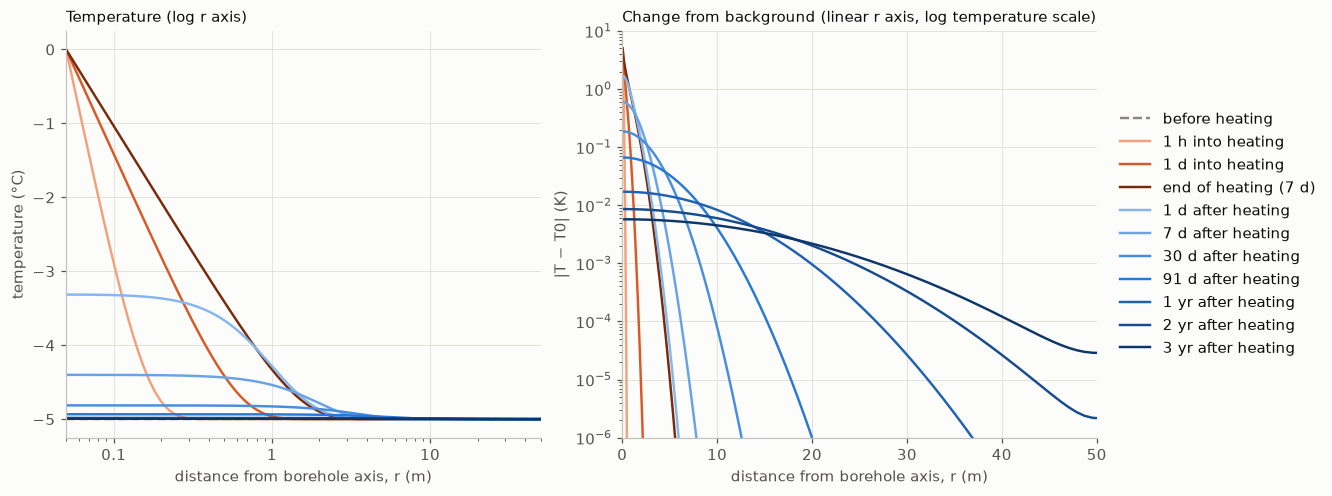

In [8]:
fig = plot_profiles(ds)

### Time series at the monitoring radii

On a log time axis measured from the start of heating. Pass `time_axis="linear"` for a linear axis, or `log_origin="heating_end"` to measure log time from the end of heating, which shows the recovery alone.

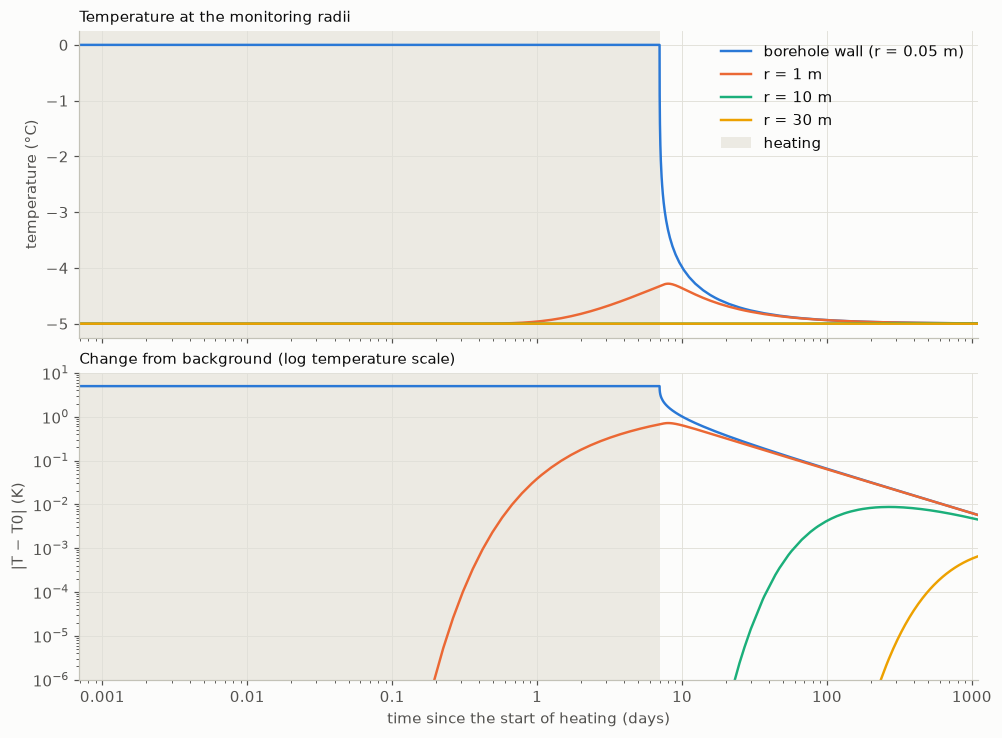

In [9]:
fig = plot_timeseries(ds, time_axis="log")

### Temperature change in time and radius

Colour shows the size of the warming on a log scale. The black contours are at each factor of ten (1 mK, 10 mK, 0.1 K, 1 K with the defaults), and the outermost one is the smallest.

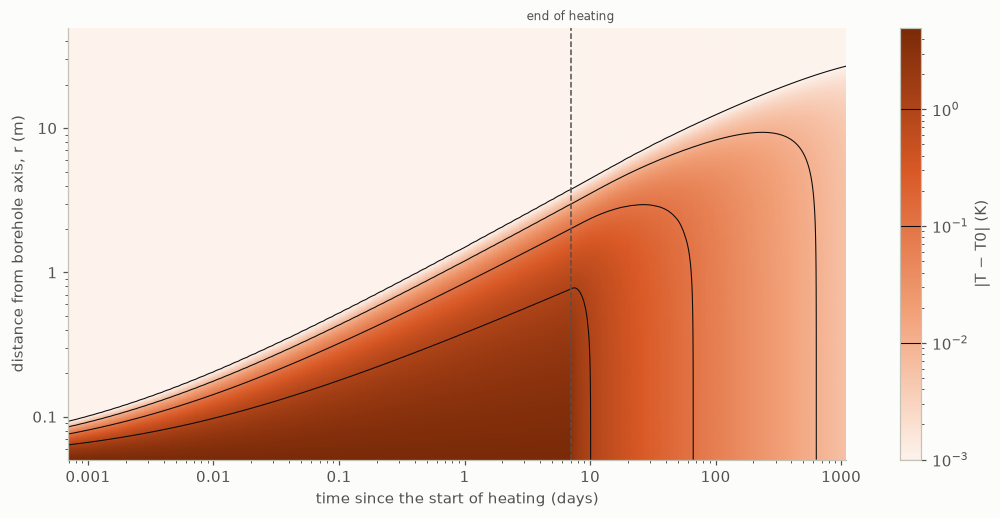

In [10]:
fig = plot_hovmoller(ds)

## 6. Save to NetCDF

The dataset holds the full field `T(time, r)`, the time series `T_monitor(time, r_monitor)`, the per-time `phase` and `inner_bc` labels, and every model parameter as a global attribute. To reload it later use `xr.open_dataset(...)`; the plotting functions above work on the reloaded dataset.

In [11]:
if params["output_file"]:
    ds.to_netcdf(params["output_file"])
    print(f"Saved {params['output_file']}")

Saved borehole_heat_diffusion.nc


## 7. Checks

### (a) Heat is conserved during recovery

With no flux through either boundary, the heat content of the ice, $\rho c \sum_i A_i (T_i - T_0)$ per metre of borehole, should stay constant once heating stops.

In [12]:
def check_heat_conservation(ds):
    """Print the relative drift of the heat content during the recovery phase."""
    in_recovery = ds["phase"].values == "recovery"
    if not in_recovery.any() or ds.attrs["inner_bc_recovery"] != "neumann":
        print("Heat is only conserved in a recovery phase with a no-flux ('neumann') borehole wall: check skipped.")
        return
    heat = ds["heat_content"].values
    heat_at_switch = heat[np.flatnonzero(in_recovery)[0] - 1]   # last output before recovery starts
    if heat_at_switch == 0:
        print("No heat was added before the recovery phase: check skipped.")
        return
    drift = heat[in_recovery] / heat_at_switch - 1
    print(f"Heat stored in the ice when heating stops: {heat_at_switch / 1e6:.3f} MJ per metre of borehole")
    print(f"Largest relative drift during recovery:    {np.abs(drift).max():.1e}")


check_heat_conservation(ds)

Heat stored in the ice when heating stops: 14.369 MJ per metre of borehole
Largest relative drift during recovery:    4.1e-13


The drift is round-off error: the scheme itself conserves heat exactly.

### (b) Grid and time-step convergence

The model is rerun with the grid spacing and every time step halved, and the temperature at 1 m is compared with the default run. Halving the time step means halving `dt_initial_s`, `dt_max_days` and (`dt_growth` − 1), which halves the step at every moment of the run. Both runs store output at the same times, so the series can be subtracted directly.

In [13]:
def refine(params, factor=2):
    """Copy of params with the grid spacing and every time step divided by `factor`."""
    refined = dict(params)
    refined["n_cells"] = params["n_cells"] * factor
    refined["dt_initial_s"] = params["dt_initial_s"] / factor
    refined["dt_growth"] = 1 + (params["dt_growth"] - 1) / factor
    refined["dt_max_days"] = params["dt_max_days"] / factor
    return refined


check_radius = 1.0   # m
ds_refined = run_model(refine(params), verbose=False)
assert np.allclose(ds_refined["time"], ds["time"]), "runs must share output times"
T_default = temperature_at_radii(ds, check_radius).isel(r_monitor=0).values
T_refined = temperature_at_radii(ds_refined, check_radius).isel(r_monitor=0).values
print(f"Largest change in T at r = {check_radius:g} m when the numerics are refined: {np.abs(T_refined - T_default).max():.1e} K")
print(f"Largest warming at r = {check_radius:g} m in the default run:               {(T_default - params['T0']).max():.3f} K")

Largest change in T at r = 1 m when the numerics are refined: 1.4e-04 K
Largest warming at r = 1 m in the default run:               0.718 K


With the default parameters the change is about 0.1 mK. Backward Euler is first-order accurate in time, so the error of the default run is about twice that change: roughly 0.3 mK against a peak warming of 0.7 K, which agrees with the comparison against the exact solution below. To reduce it, bring `dt_growth` closer to 1 (for example 1.001).

### (c) Heating phase against the exact solution

For an infinite medium initially at $T_0$ outside a cylinder whose surface is held at $T_\mathrm{hot}$ from $t = 0$, the Laplace transform of the solution is (Carslaw & Jaeger, *Conduction of Heat in Solids*, 2nd ed., §13.5)

$$\frac{\bar{T} - T_0/s}{T_\mathrm{hot} - T_0} = \frac{K_0(qr)}{s\,K_0(q r_b)}, \qquad q = \sqrt{s/\kappa},$$

where $K_0$ is a modified Bessel function. Integrating the wall heat flow in time gives the transform of the total heat delivered per metre of borehole, $2\pi r_b k\,(T_\mathrm{hot} - T_0)\,q\,K_1(q r_b)\,/\,(s^2 K_0(q r_b))$. Both are inverted numerically here with the fixed-Talbot method (Abate & Valkó, 2004, *Int. J. Numer. Meth. Engng* 60, 979–993). The comparison applies to the heating phase only, and only when it is a fixed-temperature phase that starts from a uniform temperature.

Largest |model − exact| over all radii:
     1 h into heating: 7.9e-04 K
     1 d into heating: 4.0e-04 K
     7 d into heating: 3.2e-04 K
Heat delivered by the end of heating: model 14.3689 MJ/m, exact 14.3700 MJ/m (difference -0.008 %)


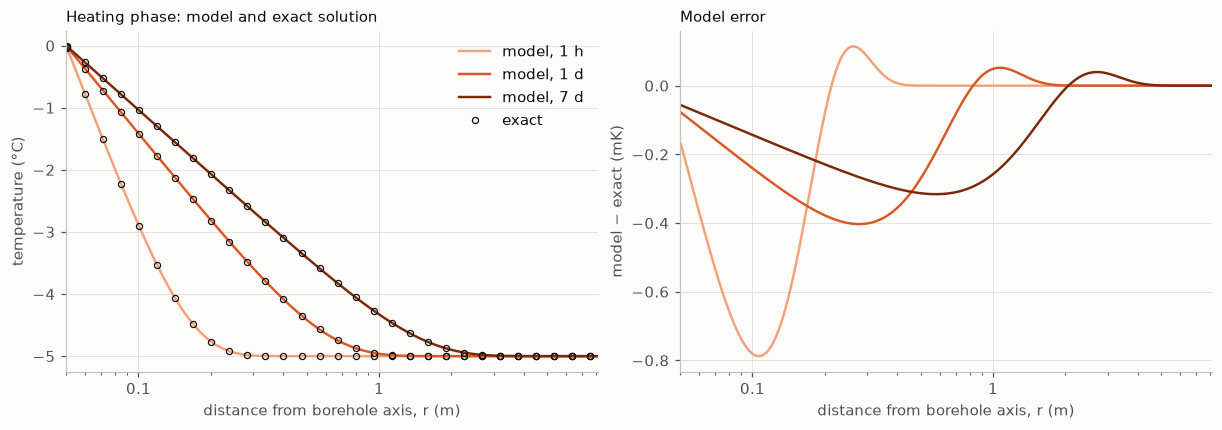

In [14]:
def invert_laplace(F, t, n_terms=32):
    """Numerical inverse Laplace transform f(t) by the fixed-Talbot method.

    F must accept a complex array s of shape (m, 1) and return an array of shape (m, n),
    so that n values (for example n radii) are inverted together.
    """
    theta = np.arange(1, n_terms) * np.pi / n_terms
    shift = 2 * n_terms / (5 * t)
    cot = 1 / np.tan(theta)
    s = shift * theta * (cot + 1j)                 # points on the Talbot contour
    sigma = theta + (theta * cot - 1) * cot
    on_contour = (np.exp(t * s) * (1 + 1j * sigma))[:, np.newaxis] * F(s[:, np.newaxis])
    on_axis = 0.5 * np.exp(shift * t) * F(np.array([[shift + 0j]]))[0]
    return (shift / n_terms) * (on_axis + on_contour.sum(axis=0)).real


def exact_heating_temperature(r, t, p):
    """Exact T(r, t) (°C) during fixed-temperature heating of an infinite medium; t in seconds."""
    kappa = p["k"] / (p["rho"] * p["c"])
    r = np.atleast_1d(np.asarray(r, dtype=float))

    def F(s):
        q = np.sqrt(s / kappa)
        # K0(q r) / K0(q r_b), written with exponentially scaled Bessel functions to avoid underflow
        return kve(0, q * r) / kve(0, q * p["r_b"]) * np.exp(-q * (r - p["r_b"])) / s

    return p["T0"] + (p["T_hot"] - p["T0"]) * invert_laplace(F, t)


def exact_heat_delivered(t, p):
    """Exact heat (J per metre of borehole) delivered to the ice after t seconds of heating."""
    kappa = p["k"] / (p["rho"] * p["c"])

    def F(s):
        q = np.sqrt(s / kappa)
        return 2 * np.pi * p["r_b"] * p["k"] * (p["T_hot"] - p["T0"]) * q * kve(1, q * p["r_b"]) / kve(0, q * p["r_b"]) / s**2

    return invert_laplace(F, t)[0]


def check_against_exact_solution(ds, params):
    """Compare the heating phase with the exact constant-temperature-cylinder solution."""
    if params["inner_bc_heating"] != "dirichlet" or params["inner_bc_spinup"] != "neumann":
        print("The exact solution needs fixed-temperature heating that starts from a uniform temperature: check skipped.")
        return None
    heating_days = params["heating_days"]
    times = [t for t in params["profile_times_heating_days"] if 0 < t < heating_days] + [heating_days]
    r = ds["r"].values
    marked = slice(None, None, max(1, r.size // 40))   # show the exact solution at every ~40th of the cells

    fig, (ax_T, ax_error) = plt.subplots(1, 2, figsize=(11, 3.8))
    print("Largest |model − exact| over all radii:")
    for t, colour in zip(times, sample_ramp(HEATING_RAMP, len(times))):
        T_model = ds["T"].sel(time=t, method="nearest").values
        T_exact = exact_heating_temperature(r, t * SECONDS_PER_DAY, params)
        print(f"  {format_duration(t):>6s} into heating: {np.abs(T_model - T_exact).max():.1e} K")
        ax_T.plot(r, T_model, color=colour, label=f"model, {format_duration(t)}")
        ax_T.plot(r[marked], T_exact[marked], "o", markersize=4, markerfacecolor="none", markeredgecolor=INK,
                  markeredgewidth=0.8, label="exact" if t == times[-1] else None)
        ax_error.plot(r, (T_model - T_exact) * 1e3, color=colour)

    heat_model = ds["heat_content"].sel(time=heating_days, method="nearest").item()
    heat_exact = exact_heat_delivered(heating_days * SECONDS_PER_DAY, params)
    print(f"Heat delivered by the end of heating: model {heat_model / 1e6:.4f} MJ/m, exact {heat_exact / 1e6:.4f} MJ/m "
          f"(difference {100 * (heat_model / heat_exact - 1):+.3f} %)")

    for ax in (ax_T, ax_error):
        ax.set_xscale("log")
        ax.xaxis.set_major_formatter("{x:g}")
        ax.set_xlim(params["r_b"], 10 * np.sqrt(params["k"] / (params["rho"] * params["c"]) * heating_days * SECONDS_PER_DAY))
        ax.set_xlabel("distance from borehole axis, r (m)")
    ax_T.set_ylabel("temperature (°C)")
    ax_T.set_title("Heating phase: model and exact solution")
    ax_T.legend(loc="upper right")
    ax_error.set_ylabel("model − exact (mK)")
    ax_error.set_title("Model error")
    return fig


fig = check_against_exact_solution(ds, params)

With the default parameters the model is within 1 mK of the exact solution at every radius, and the heat delivered to the ice agrees to about 0.01 %. The error is largest early in the heating phase, close to the borehole, where the temperature changes fastest.

## 8. Rerun with different parameters

`run_model` takes a parameter dictionary and returns a dataset, so a different case is a modified copy of `params`. This example varies the heating duration and overlays the temperature at 1 m.

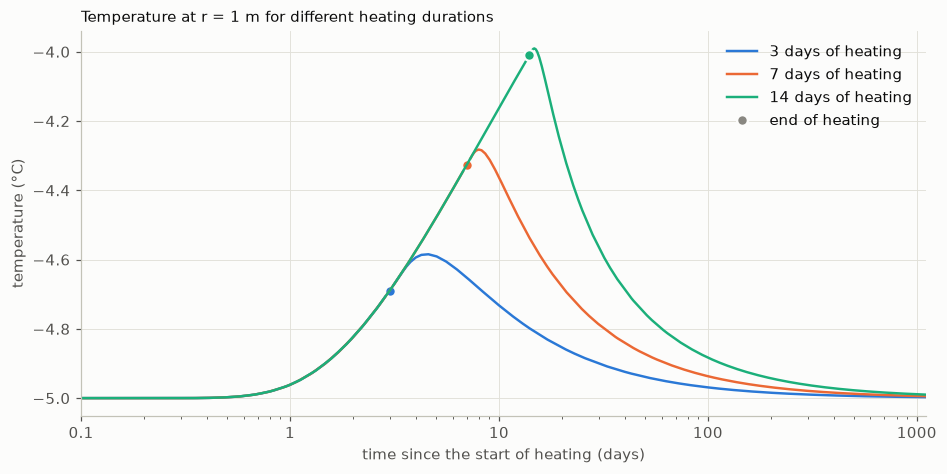

In [15]:
sweep_radius = 1.0                # m
sweep_heating_days = [3, 7, 14]

fig, ax = plt.subplots(figsize=(8.5, 4.2))
for days, colour in zip(sweep_heating_days, SERIES_COLOURS):
    ds_case = run_model({**params, "heating_days": days}, verbose=False)
    T_case = temperature_at_radii(ds_case, sweep_radius).isel(r_monitor=0)
    after_start = T_case["time"].values > 0
    ax.plot(T_case["time"].values[after_start], T_case.values[after_start], color=colour,
            label=f"{days:g} days of heating")
    # Dot where this case stops heating
    ax.plot(days, T_case.sel(time=days, method="nearest").item(), "o", markersize=7, color=colour,
            markeredgecolor=SURFACE, markeredgewidth=1.5)
ax.plot([], [], "o", markersize=7, color=INK_MUTED, markeredgecolor=SURFACE, markeredgewidth=1.5, label="end of heating")
ax.set_xscale("log")
ax.xaxis.set_major_formatter("{x:g}")
ax.set_xlim(0.1, max(sweep_heating_days) + params["recovery_days"])
ax.set_xlabel("time since the start of heating (days)")
ax.set_ylabel("temperature (°C)")
ax.set_title(f"Temperature at r = {sweep_radius:g} m for different heating durations")
ax.legend(loc="upper right")
plt.show()

Any other parameter can be changed the same way, for example:

```python
ds_wide = run_model({**params, "r_b": 0.10})                       # wider borehole
ds_cold = run_model({**params, "T0": -20.0, "R_max": 80.0})        # colder ice, larger domain
ds_held = run_model({**params, "inner_bc_recovery": "dirichlet"})  # wall kept at T_hot after heating
fig = plot_profiles(ds_wide)
```

## 9. Borehole temperature after heating

In the field only the temperature in the borehole can be measured, some time after the hole has been at the melting point. This section looks at the model's borehole temperature during recovery, which is the temperature at the borehole wall (`T_wall`). Sections 10 and 11 then ask how well the undisturbed ice temperature $T_0$ can be recovered from it.

Two things to keep in mind when reading the results:

- The disturbance $T - T_0$ is proportional to $T_\mathrm{hot} - T_0$. Results for another background temperature follow by scaling, which the third panel below shows.
- The model has no latent heat. A water-filled hole stays at the melting point until it has refrozen, so when applying these results the heating duration should cover that whole time and not only the drilling. For scale, refreezing a water-filled hole of 5 cm radius releases 2.6 MJ of latent heat per metre of borehole, about what the model delivers to the ice in one day of heating with the default parameters (3.0 MJ per metre).

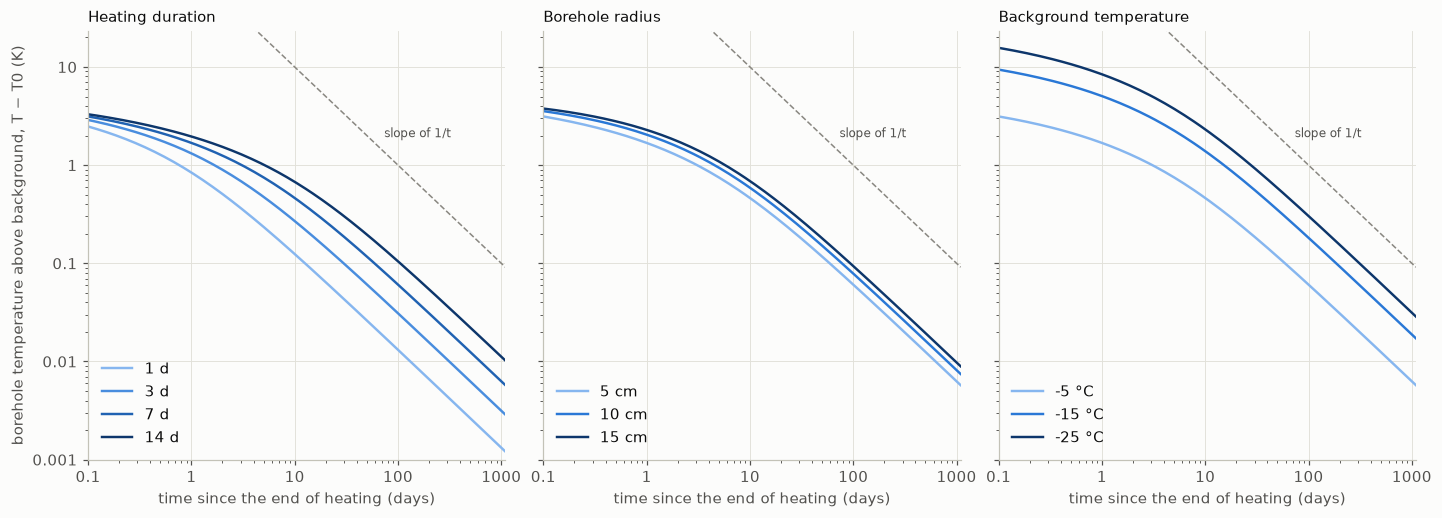

In [16]:
# Days after the end of heating on which the borehole temperature can be read in sections 9 to 11.
# Passing them to the model as profile times makes the solver store output on exactly these days.
reading_days = np.arange(1, 731, dtype=float)   # every day for two years


def run_case(**changes):
    """Run the model with some parameters changed, storing output on every reading day.

    Output is also stored more densely than the default, so that curves against 1/t are smooth.
    """
    return run_model({**params, "profile_times_recovery_days": reading_days, "n_output_log": 200, **changes},
                     verbose=False)


def borehole_recovery(ds):
    """Days since heating ended, and borehole-wall temperature (°C), for the whole recovery phase."""
    in_recovery = ds["phase"].values == "recovery"
    return ds["time"].values[in_recovery] - float(ds.attrs["heating_days"]), ds["T_wall"].values[in_recovery]


def borehole_temperature(ds, days_after_heating):
    """Borehole-wall temperature (°C) on given days after the end of heating.

    The days must be stored output times, so that nothing is interpolated in time.
    """
    wanted = float(ds.attrs["heating_days"]) + np.atleast_1d(np.asarray(days_after_heating, dtype=float))
    picked = ds["T_wall"].sel(time=wanted, method="nearest")
    if not np.allclose(picked["time"].values, wanted, rtol=0, atol=1e-6):
        raise ValueError("Some of these days are not stored output times. They must be in reading_days "
                         "and fall within the recovery phase.")
    return picked.values


# One group of runs per parameter that is varied. Everything else keeps its value from section 2.
recovery_sweeps = {
    "Heating duration": {f"{days:g} d": {"heating_days": days} for days in (1, 3, 7, 14)},
    "Borehole radius": {f"{100 * radius:g} cm": {"r_b": radius} for radius in (0.05, 0.10, 0.15)},
    "Background temperature": {f"{T_background:g} °C": {"T0": T_background} for T_background in (-5.0, -15.0, -25.0)},
}
recovery_runs = {sweep: {label: run_case(**changes) for label, changes in cases.items()}
                 for sweep, cases in recovery_sweeps.items()}
heating_runs = recovery_runs["Heating duration"]   # runs with 1, 3, 7 and 14 days of heating


def plot_borehole_recovery(recovery_runs, dT_min=1e-3, t_min=0.1):
    """Borehole temperature above background against time since heating ended, one panel per sweep."""
    fig, axes = plt.subplots(1, len(recovery_runs), figsize=(13, 4.6), sharex=True, sharey=True, squeeze=False)
    dT_max = 0.0
    for ax, (sweep, runs) in zip(axes[0], recovery_runs.items()):
        lines = []
        for (label, ds_case), colour in zip(runs.items(), sample_ramp(RECOVERY_RAMP, len(runs))):
            t, T = borehole_recovery(ds_case)
            disturbance = T - float(ds_case.attrs["T0"])
            lines += ax.plot(t, disturbance, color=colour, label=label)
            dT_max = max(dT_max, disturbance[t >= t_min].max())
        # Guide line with the slope of the late-time 1/t decay
        t_guide = np.array([3.0, params["recovery_days"]])
        ax.plot(t_guide, 100 / t_guide, color=INK_MUTED, linewidth=1, linestyle="--")
        ax.annotate("slope of 1/t", (60, 100 / 60), xytext=(6, 4), textcoords="offset points", fontsize=8,
                    color=INK_SOFT)
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.xaxis.set_major_formatter("{x:g}")
        ax.yaxis.set_major_formatter("{x:g}")
        ax.set_xlim(t_min, params["recovery_days"])
        ax.set_xlabel("time since the end of heating (days)")
        ax.set_title(sweep)
        ax.legend(handles=lines, loc="lower left")
    axes[0, 0].set_ylim(dT_min, 1.5 * dT_max)
    axes[0, 0].set_ylabel("borehole temperature above background, T − T0 (K)")
    return fig


def print_recovery_table(recovery_runs, days=(7, 14, 21, 365, 730)):
    """Print T - T0 (K) in the borehole on selected days after the end of heating."""
    print("Borehole temperature above background, T − T0 (K), after the end of heating")
    print(" " * 32 + "".join(f"{format_duration(day):>10}" for day in days))
    for sweep, runs in recovery_runs.items():
        for label, ds_case in runs.items():
            dT = borehole_temperature(ds_case, days) - float(ds_case.attrs["T0"])
            print(f"{sweep + ' ' + label:<32}" + "".join(f"{value:10.4f}" for value in dT))


fig = plot_borehole_recovery(recovery_runs)

In [17]:
print_recovery_table(recovery_runs)

Borehole temperature above background, T − T0 (K), after the end of heating
                                       7 d      14 d      21 d      1 yr      2 yr
Heating duration 1 d                0.1732    0.0903    0.0611    0.0036    0.0018
Heating duration 3 d                0.3636    0.2005    0.1386    0.0086    0.0043
Heating duration 7 d                0.5992    0.3562    0.2545    0.0171    0.0086
Heating duration 14 d               0.8402    0.5392    0.4007    0.0302    0.0153
Borehole radius 5 cm                0.5992    0.3562    0.2545    0.0171    0.0086
Borehole radius 10 cm               0.7581    0.4551    0.3266    0.0222    0.0112
Borehole radius 15 cm               0.8814    0.5345    0.3854    0.0266    0.0134
Background temperature -5 °C        0.5992    0.3562    0.2545    0.0171    0.0086
Background temperature -15 °C       1.7976    1.0685    0.7634    0.0513    0.0258
Background temperature -25 °C       2.9960    1.7808    1.2724    0.0855    0.0430


## 10. Estimating the undisturbed temperature

Long after heating, the heat $Q$ left in the ice per metre of borehole behaves as if it had been released all at once along a line, and the borehole temperature approaches

$$T(t) = T_0 + \frac{Q}{4\pi k\,t}.$$

This is the relation Humphrey and Echelmeyer (1990, *J. Glaciol.* 36, 287–298) give for sensors frozen into hot-water-drilled holes, as quoted by McDowell et al. (2021, *The Cryosphere* 15, 897–907, supplement eq. S2). Plotted against $1/t$ the temperature is a straight line, and its intercept at $1/t = 0$ is $T_0$. Neither $Q$ nor $k$ needs to be known.

The straight line is only reached when $t$ is much longer than the heating duration $s$, because the heat was delivered over a finite time and not all at once. For a source of constant power lasting a time $s$, the corresponding result is $T = T_0 + \dfrac{Q}{4\pi k\,s}\ln(1 + s/t)$ (Lachenbruch and Brewer, 1959, *U.S. Geological Survey Bulletin* 1083-C), which bends away from the $1/t$ line when $t$ is comparable to $s$.

Three fits are used below, with $t$ measured from the end of heating:

- **1/t fit:** a least-squares straight line through $T$ against $1/t$. The intercept is the estimate of $T_0$.
- **ln(1 + s/t) fit:** the same, with $\ln(1 + s/t)$ on the horizontal axis. This needs the heating duration $s$.
- **Free time shift:** $T = T_0 + A/(t + t_0)$, with the shift $t_0$ fitted along with $T_0$ and $A$. The shift allows for the heat having been delivered over a period before $t = 0$, so the heating duration is not needed, but there must be at least three readings.

The readings are the model's borehole temperature with no measurement noise, so the errors below are the errors of the methods themselves. Each fit also has a noise factor: the standard deviation of its estimate divided by the standard deviation of a single reading, for independent reading errors.

In [18]:
# Functions of time (t = days since heating ended, s = heating duration in days) that tend to
# zero as t tends to infinity. T is fitted against one of them and extrapolated to zero.
TIME_FUNCTIONS = {
    "1/t fit": lambda t, s: 1 / t,
    "ln(1 + s/t) fit": lambda t, s: np.log(1 + s / t),
}
# d ln(x) / d ln(t) for each of those time functions x(t)
TIME_FUNCTION_LOG_SLOPES = {
    "1/t fit": lambda t, s: -np.ones_like(t),
    "ln(1 + s/t) fit": lambda t, s: -(s / (t + s)) / np.log(1 + s / t),
}
FIT_AXIS_LABELS = {
    "1/t fit": "1 / (days since the end of heating)",
    "ln(1 + s/t) fit": "ln(1 + s/t), where s is the heating duration and t the time since the end of heating",
}
TIME_SHIFT = "free time shift"
FITS = [*TIME_FUNCTIONS, TIME_SHIFT]


def estimate_T0(days, T, heating_days=None, method="1/t fit"):
    """Estimate the undisturbed temperature from borehole temperatures T (°C) read on `days` after heating.

    method is "1/t fit", "ln(1 + s/t) fit" (which needs heating_days) or "free time shift".
    Returns (estimate, noise factor).
    """
    days, T = np.asarray(days, dtype=float), np.asarray(T, dtype=float)
    if method == TIME_SHIFT:
        slope, intercept = np.polyfit(1 / days, T, 1)   # start from the plain 1/t fit
        fit = least_squares(lambda p: p[0] + p[1] / (days + p[2]) - T, x0=[intercept, slope, 0.0], method="lm",
                            xtol=1e-14, ftol=1e-14, gtol=1e-14)
        T0, A, t0 = fit.x
        jacobian = np.column_stack([np.ones_like(days), 1 / (days + t0), -A / (days + t0) ** 2])
        return T0, np.sqrt(np.linalg.inv(jacobian.T @ jacobian)[0, 0])
    x = TIME_FUNCTIONS[method](days, heating_days)
    slope, intercept = np.polyfit(x, T, 1)
    return intercept, np.sqrt(np.sum(x**2) / (x.size * np.sum((x - x.mean()) ** 2)))


def plot_fits(ds_case, reading_sets, later_than_day=7.1):
    """Borehole temperature against the time function of each straight-line fit, with fits to some sets of readings.

    reading_sets is a dictionary {label: days}. One column per fit. The top row shows every
    reading; the bottom row shows only the readings taken after later_than_day.
    """
    T0, heating_days = float(ds_case.attrs["T0"]), float(ds_case.attrs["heating_days"])
    t_model, T_model = borehole_recovery(ds_case)
    from_day_1 = t_model >= 0.95
    shown_days = np.append(np.arange(1.0, 22.0), 365.0)   # readings drawn as dots
    T_shown = borehole_temperature(ds_case, shown_days)
    fig, axes = plt.subplots(2, len(TIME_FUNCTIONS), figsize=(6.4 * len(TIME_FUNCTIONS), 7.6), squeeze=False)
    for column, (method, time_function) in enumerate(TIME_FUNCTIONS.items()):
        x_shown = time_function(shown_days, heating_days)
        lines = {}   # label: (intercept, slope, largest x fitted)
        for label, days in reading_sets.items():
            days = np.asarray(days, dtype=float)
            slope, intercept = np.polyfit(time_function(days, heating_days), borehole_temperature(ds_case, days), 1)
            lines[label] = (intercept, slope, time_function(days.min(), heating_days))
        x_limits = (1.05 * time_function(1.0, heating_days), time_function(later_than_day, heating_days))
        for row, x_max in enumerate(x_limits):
            ax = axes[row, column]
            ax.axhline(T0, color=INK_SOFT, linewidth=1, linestyle="--", label="true T0")
            ax.plot(time_function(t_model[from_day_1], heating_days), T_model[from_day_1], color=INK_MUTED,
                    linewidth=1, label="model")
            for (label, (intercept, slope, x_end)), colour in zip(lines.items(), SERIES_COLOURS):
                ax.plot([0, x_end], [intercept, intercept + slope * x_end], color=colour, label=f"fit to {label}")
                ax.plot(0, intercept, "o", markersize=8, color=colour, markeredgecolor=SURFACE,
                        markeredgewidth=1.5, clip_on=False, zorder=5)
            ax.plot(x_shown, T_shown, "o", markersize=4, color=INK, label="readings", zorder=4)
            # Name a few of the readings by the day they were taken
            for day in ((1, 2, 3, 7) if row == 0 else (8, 14, 21, 365)):
                if time_function(day, heating_days) <= x_max:
                    ax.annotate(format_duration(day) if day >= 365 else f"day {day}",
                                (time_function(day, heating_days), borehole_temperature(ds_case, day)[0]),
                                xytext=(5, -11), textcoords="offset points", fontsize=8, color=INK_SOFT)
            ax.set_xlim(0, x_max)
            top = max(T_shown[x_shown <= x_max].max(), max(intercept for intercept, _, _ in lines.values()))
            ax.set_ylim(T0 - 0.08 * (top - T0), top + 0.08 * (top - T0))
            ax.set_ylabel("borehole temperature (°C)")
            ax.set_title(f"{method}, {format_duration(heating_days)} of heating" + (": later readings" if row else ""))
        axes[1, column].set_xlabel(FIT_AXIS_LABELS[method])
    axes[0, -1].legend(loc="lower right")
    return fig


def fraction_left_by_fit(ds, method="1/t fit", points_per_decade=24):
    """Error of a straight-line fit to readings taken close to time t, as a fraction of the disturbance at time t.

    Returns (t in days since heating ended, fraction). A line through readings that are close
    together is the tangent to the curve of T against the fit's time function x(t), which gives
    fraction = 1 - [d ln(T - T0) / d ln(t)] / [d ln(x) / d ln(t)]. The slope of the disturbance
    comes from a cubic spline through the stored output on log-log axes.
    """
    t, T = borehole_recovery(ds)
    heating_days = float(ds.attrs["heating_days"])
    log_t_stored, log_disturbance_stored = np.log(t), np.log(T - float(ds.attrs["T0"]))
    # Thin the stored output so that neighbouring spline knots are not almost on top of each other
    knots = [0]
    for index in range(1, t.size):
        if log_t_stored[index] - log_t_stored[knots[-1]] >= 0.06:
            knots.append(index)
    spline = CubicSpline(log_t_stored[knots], log_disturbance_stored[knots])
    n_points = int(points_per_decade * np.log10(t[knots[-1]] / t[0])) + 1
    log_t = np.linspace(log_t_stored[0], log_t_stored[knots[-1]], n_points)
    t = np.exp(log_t)
    return t, 1 - spline(log_t, 1) / TIME_FUNCTION_LOG_SLOPES[method](t, heating_days)


def plot_waiting_time(heating_runs, fraction_min=0.01):
    """Fraction of the disturbance left by each straight-line fit, against time in heating durations.

    The panels stop at fraction_min: below about 0.01 the result is limited by the numerical
    accuracy of the model.
    """
    fig, axes = plt.subplots(1, len(TIME_FUNCTIONS), figsize=(12.5, 4.4), sharex=True, sharey=True)
    for ax, method in zip(axes, TIME_FUNCTIONS):
        for (label, ds_case), colour in zip(heating_runs.items(), sample_ramp(RECOVERY_RAMP, len(heating_runs))):
            t, fraction = fraction_left_by_fit(ds_case, method)
            ax.plot(t / float(ds_case.attrs["heating_days"]), np.abs(fraction), color=colour,
                    label=f"{label} of heating")
        if method == "1/t fit":
            t_over_s = np.geomspace(0.1, 100, 100)
            ax.plot(t_over_s, 1 / (1 + 2 * t_over_s), color=INK, linewidth=1, linestyle=":", label="s / (s + 2t)")
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.xaxis.set_major_formatter("{x:g}")
        ax.yaxis.set_major_formatter("{x:g}")
        ax.set_xlim(0.1, 100)
        ax.set_ylim(fraction_min, 1.5)
        ax.set_xlabel("time since the end of heating ÷ heating duration, t / s")
        ax.set_title(method)
        ax.legend(loc="lower left")
    axes[0].set_ylabel("error of the fit ÷ error of the reading itself")
    return fig

### What the fits look like

Borehole temperature after seven days of heating, plotted against $1/t$ (left) and against $\ln(1 + s/t)$ (right). The top row shows all the readings; the bottom row zooms in on the later ones. Each coloured line is a least-squares fit to one set of readings, extended to zero on the horizontal axis, where the large dot is its estimate of $T_0$. The dashed line is the true $T_0$.

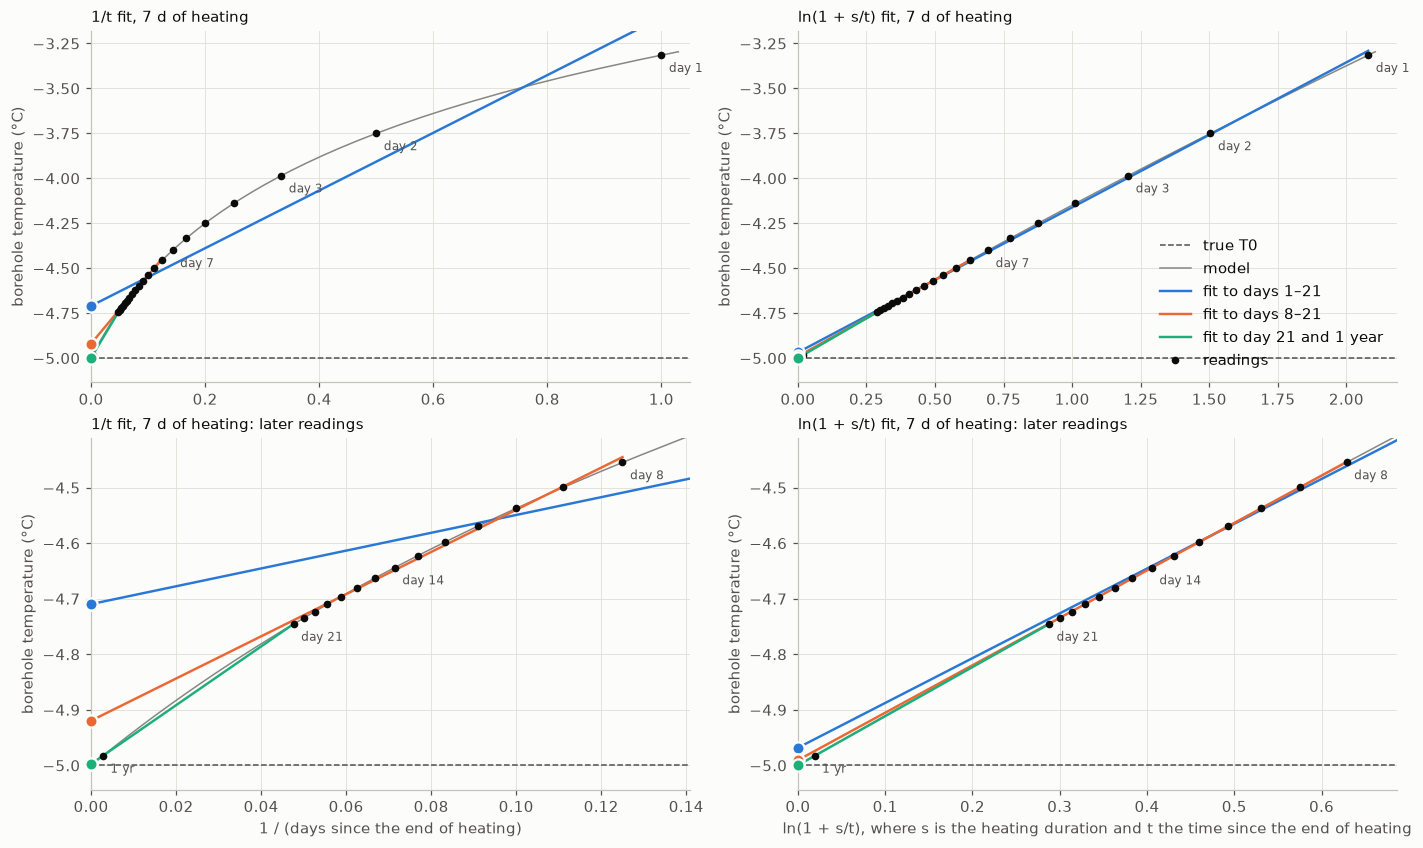

In [19]:
fig = plot_fits(heating_runs["7 d"], {"days 1–21": np.arange(1, 22), "days 8–21": np.arange(8, 22),
                                      "day 21 and 1 year": [21, 365]})

### How long to wait

A straight line through readings that are all taken close to a time $t$ is the tangent to the curves above, and its intercept misses $T_0$ by some fraction of the disturbance present at that time. The figure shows that fraction against time measured in heating durations.

For the 1/t fit the curves for different heating durations nearly coincide, and follow $s/(s + 2t)$. For the ln(1 + s/t) fit they are lower and do not coincide: that fit assumes heat was delivered at a constant rate, but with the wall held at a fixed temperature the rate falls as heating goes on, and proportionally more over a short heating period.

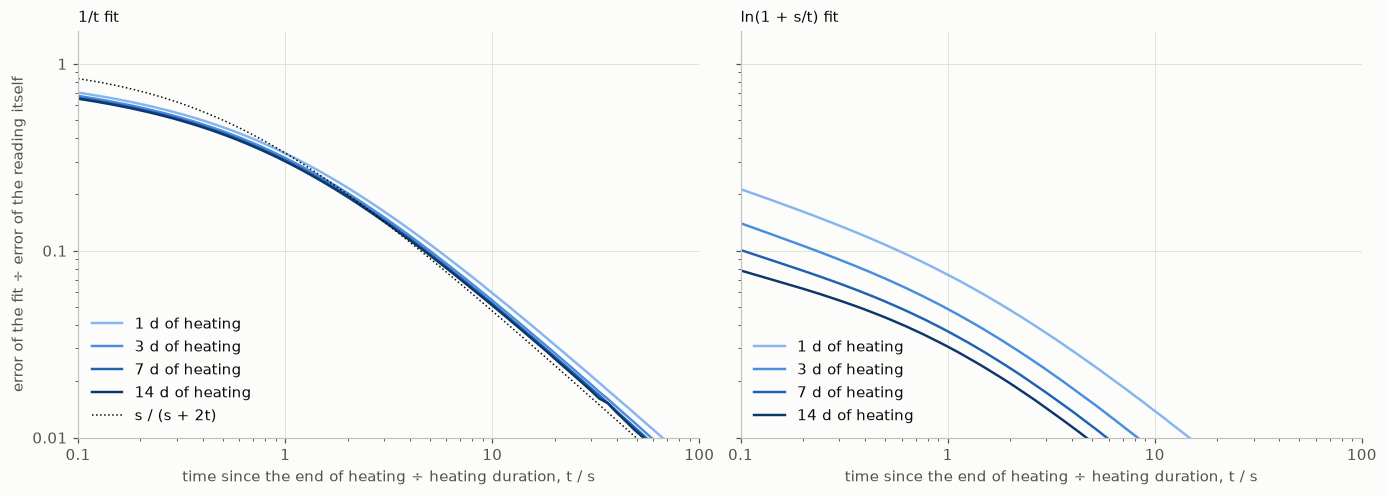

In [20]:
fig = plot_waiting_time(heating_runs)

## 11. Survey design: how long and how often to measure

Two design questions:

1. Is one return visit, a year after drilling, enough, or is a second visit at two years needed?
2. Is near-continuous logging needed, or are a few readings in the first weeks and one a year later enough?

### A few readings

Each row of the tables is a set of reading days, counted from the end of heating. Each column is a way of turning those readings into an estimate of $T_0$: the last reading taken at face value, a line through the last two readings, or a fit to all of them. The first tables give the method error with noise-free readings; positive means too warm. The next gives the noise factors, and the last shows what happens to the ln(1 + s/t) line if the heating duration is misjudged.

In [21]:
# Reading days, counted from the end of heating, in each design
designs = {
    "days 7, 14, 21": [7, 14, 21],
    "days 7, 14, 21 + 1 yr": [7, 14, 21, 365],
    "days 7, 14, 21 + 1 yr + 2 yr": [7, 14, 21, 365, 730],
    "days 2, 4, 7 + 1 yr": [2, 4, 7, 365],
    "1 yr + 2 yr": [365, 730],
}
# Ways of estimating T0 from the readings of a design: (fit, which readings it uses)
estimators = {
    "1/t line, last 2": ("1/t fit", slice(-2, None)),
    "1/t fit, all": ("1/t fit", slice(None)),
    "ln line, last 2": ("ln(1 + s/t) fit", slice(-2, None)),
    "time shift, all": (TIME_SHIFT, slice(None)),
}


def design_errors(ds, days, assumed_heating_days=None):
    """Method error (K) and noise factor of each estimator, for readings on the given days.

    Returns {estimator: (error, noise factor)}. Positive errors are too warm. assumed_heating_days
    is the heating duration given to the ln(1 + s/t) fit, if it differs from the true one.
    """
    days = np.asarray(days, dtype=float)
    T0 = float(ds.attrs["T0"])
    heating_days = float(ds.attrs["heating_days"]) if assumed_heating_days is None else assumed_heating_days
    T = borehole_temperature(ds, days)
    results = {"last reading": (T[-1] - T0, 1.0)}
    for name, (method, used) in estimators.items():
        if method == TIME_SHIFT and days[used].size < 3:
            results[name] = (np.nan, np.nan)   # three numbers cannot be fitted to two readings
        else:
            estimate, noise_factor = estimate_T0(days[used], T[used], heating_days, method)
            results[name] = (estimate - T0, noise_factor)
    return results


def print_design_table(title, rows, scale=1.0, decimals=1):
    """Print one number per design (row) and estimator (column); rows is {design: {estimator: value}}."""
    columns = ["last reading", *estimators]
    print(f"\n{title}")
    print(" " * 30 + "".join(f"{column:>18}" for column in columns))
    for design, values in rows.items():
        cells = [f"{scale * values[column]:18.{decimals}f}" if np.isfinite(values[column]) else f"{'–':>18}"
                 for column in columns]
        print(f"{design:<30}" + "".join(cells))


all_design_errors = {label: {design: design_errors(ds_case, days) for design, days in designs.items()}
                     for label, ds_case in heating_runs.items()}
for label, by_design in all_design_errors.items():
    print_design_table(f"Heating for {label}: method error in the estimate of T0 (mK)",
                       {design: {name: error for name, (error, _) in results.items()}
                        for design, results in by_design.items()}, scale=1e3)
print_design_table("Noise factor of each estimate (7 days of heating; it changes little with heating duration)",
                   {design: {name: factor for name, (_, factor) in results.items()}
                    for design, results in all_design_errors["7 d"].items()}, decimals=2)

# The ln(1 + s/t) line needs the heating duration. What if it is wrong by a factor of two?
print("\nln line through day 21 and 1 yr when the heating duration is misjudged: method error (mK)")
print(f"{'':<16}{'assumed half':>16}{'correct':>16}{'assumed double':>16}")
for label, ds_case in heating_runs.items():
    true_days = float(ds_case.attrs["heating_days"])
    errors = [design_errors(ds_case, [21, 365], factor * true_days)["ln line, last 2"][0] for factor in (0.5, 1.0, 2.0)]
    print(f"{'Heating for ' + label:<16}" + "".join(f"{1e3 * error:16.1f}" for error in errors))


Heating for 1 d: method error in the estimate of T0 (mK)
                                    last reading  1/t line, last 2      1/t fit, all   ln line, last 2   time shift, all
days 7, 14, 21                              61.1               2.7               5.8               0.6               0.1
days 7, 14, 21 + 1 yr                        3.6               0.1               2.3               0.0               0.0
days 7, 14, 21 + 1 yr + 2 yr                 1.8               0.0               1.4               0.0               0.0
days 2, 4, 7 + 1 yr                          3.6               0.3              18.0               0.1               0.1
1 yr + 2 yr                                  1.8               0.0               0.0               0.0                 –

Heating for 3 d: method error in the estimate of T0 (mK)
                                    last reading  1/t line, last 2      1/t fit, all   ln line, last 2   time shift, all
days 7, 14, 21                       

### Near-continuous logging

Now suppose a logger records the borehole temperature once a day. With that many readings, what is left to choose is which fit to use and which readings to put into it. Two things pull in opposite directions:

- Starting the fit later reduces the method error, because later readings are closer to the long-time decay.
- Starting later leaves fewer readings, spread over a shorter stretch of the fitting axis, so noise in the readings is amplified more.

The figure shows both for a logger that runs for one year: the method error (top; values below 0.01 mK are beyond the numerical accuracy of the model and are drawn at 0.01 mK) and the noise factor (bottom), against the first day used in the fit. The table then combines them for the reading noise levels in `reading_noise_mK`, as expected error $= \sqrt{\text{method error}^2 + (\text{noise factor} \times \text{reading noise})^2}$, and gives the first day that minimises it, for loggers running one year and two years.

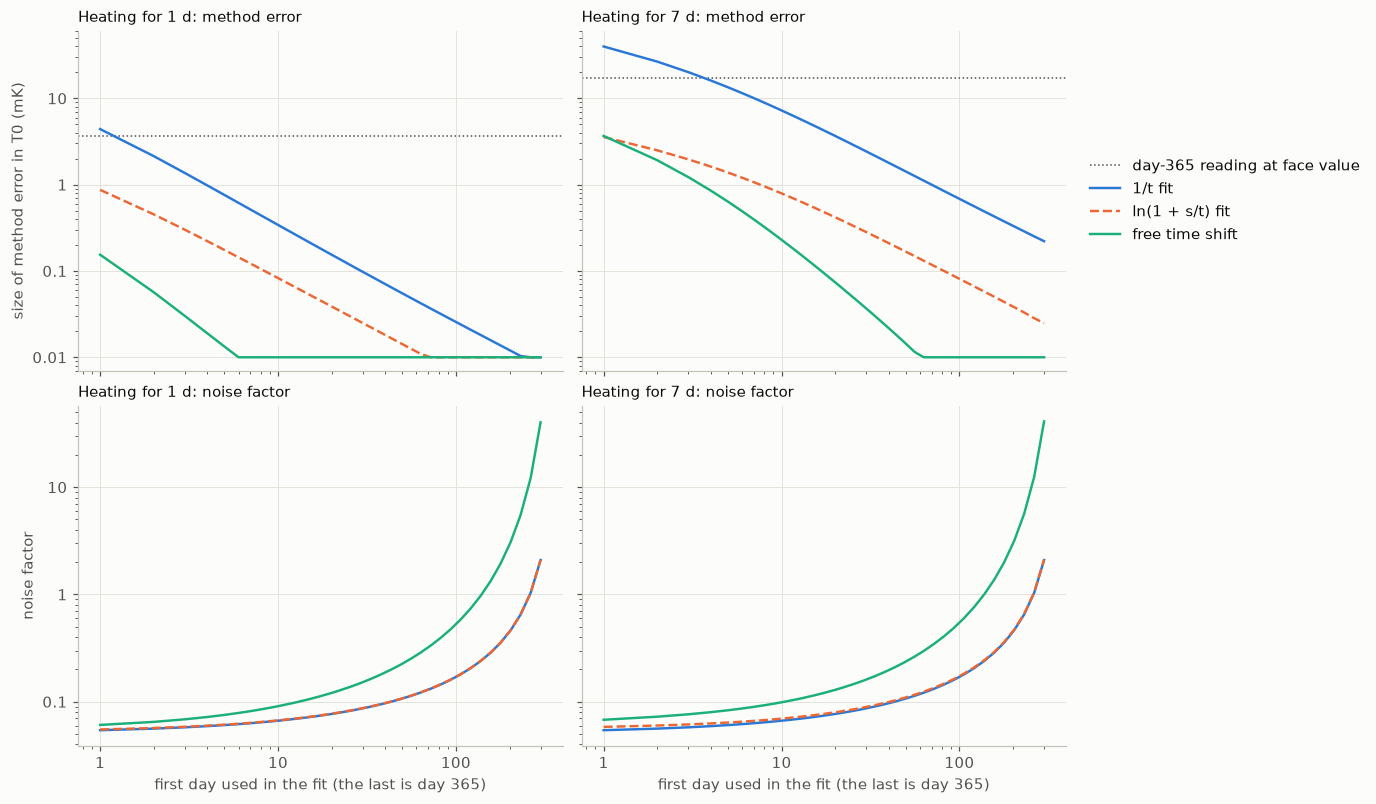

In [22]:
reading_noise_mK = [1.0, 10.0]   # standard deviation of one reading (mK)
logging_years = [1, 2]           # how long the logger runs


def scan_first_day(ds, last_day):
    """Method error (K) and noise factor of each fit to the daily readings from each first day up to last_day.

    Returns (first days, {fit: (method errors, noise factors)}).
    """
    T0, heating_days = float(ds.attrs["T0"]), float(ds.attrs["heating_days"])
    days = reading_days[reading_days <= last_day]
    T = borehole_temperature(ds, days)
    first_days = np.unique(np.round(np.geomspace(1, 0.82 * last_day, 45)))
    errors, factors = {fit: [] for fit in FITS}, {fit: [] for fit in FITS}
    for first_day in first_days:
        used = days >= first_day
        for fit in FITS:
            estimate, noise_factor = estimate_T0(days[used], T[used], heating_days, fit)
            errors[fit].append(estimate - T0)
            factors[fit].append(noise_factor)
    return first_days, {fit: (np.array(errors[fit]), np.array(factors[fit])) for fit in FITS}


def best_first_day(scan, fit, noise_mK):
    """First day that minimises the expected error of a fit, and that expected error (mK)."""
    first_days, results = scan
    method_error, noise_factor = results[fit]
    expected = np.hypot(1e3 * method_error, noise_factor * noise_mK)
    return first_days[np.argmin(expected)], expected.min()


def plot_first_day_scan(scans, last_day, labels=("1 d", "7 d"), floor_mK=0.01):
    """Method error and noise factor of each fit against the first day used, one column per heating duration.

    Method errors smaller than floor_mK are drawn at floor_mK: they are at the numerical accuracy of the model.
    """
    styles = {   # fit: (colour, line style)
        "1/t fit": (SERIES_COLOURS[0], "-"),
        "ln(1 + s/t) fit": (SERIES_COLOURS[1], "--"),
        TIME_SHIFT: (SERIES_COLOURS[2], "-"),
    }
    fig, axes = plt.subplots(2, len(labels), figsize=(6.2 * len(labels), 7.2), sharex=True, sharey="row", squeeze=False)
    for column, label in enumerate(labels):
        first_days, results = scans[label]
        ds_case = heating_runs[label]
        face_value_mK = 1e3 * (borehole_temperature(ds_case, last_day)[0] - float(ds_case.attrs["T0"]))
        ax_error, ax_noise = axes[:, column]
        ax_error.axhline(face_value_mK, color=INK_SOFT, linewidth=1, linestyle=":",
                         label=f"day-{last_day} reading at face value")
        for fit, (colour, line_style) in styles.items():
            method_error, noise_factor = results[fit]
            ax_error.plot(first_days, np.maximum(np.abs(1e3 * method_error), floor_mK), color=colour,
                          linestyle=line_style, label=fit)
            ax_noise.plot(first_days, noise_factor, color=colour, linestyle=line_style, label=fit)
        ax_error.set_title(f"Heating for {label}: method error")
        ax_noise.set_title(f"Heating for {label}: noise factor")
        ax_noise.set_xlabel(f"first day used in the fit (the last is day {last_day})")
        for ax in (ax_error, ax_noise):
            ax.set_xscale("log")
            ax.set_yscale("log")
            ax.xaxis.set_major_formatter("{x:g}")
            ax.yaxis.set_major_formatter("{x:g}")
    axes[0, 0].set_ylim(0.7 * floor_mK, None)
    axes[0, 0].set_ylabel("size of method error in T0 (mK)")
    axes[1, 0].set_ylabel("noise factor")
    axes[0, -1].legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
    return fig


# scans[years][heating duration] for a logger running that many years
scans = {years: {label: scan_first_day(ds_case, 365 * years) for label, ds_case in heating_runs.items()}
         for years in logging_years}
fig = plot_first_day_scan(scans[1], last_day=365)

In [23]:
print("Daily logging: best first day for each fit, and the expected error (mK) it gives")
for label in heating_runs:
    print(f"\nHeating for {label}")
    print(" " * 18 + "".join(f"{f'{years} yr, noise {noise:g} mK':>24}"
                             for years in logging_years for noise in reading_noise_mK))
    for fit in FITS:
        cells = []
        for years in logging_years:
            for noise in reading_noise_mK:
                first_day, expected = best_first_day(scans[years][label], fit, noise)
                cells.append(f"{f'day {first_day:.0f}: {expected:.2f}':>24}")
        print(f"{fit:<18}" + "".join(cells))

Daily logging: best first day for each fit, and the expected error (mK) it gives

Heating for 1 d
                          1 yr, noise 1 mK       1 yr, noise 10 mK        2 yr, noise 1 mK       2 yr, noise 10 mK
1/t fit                       day 43: 0.12            day 12: 0.74            day 51: 0.07            day 12: 0.47
ln(1 + s/t) fit               day 20: 0.09             day 5: 0.64            day 21: 0.05             day 5: 0.42
free time shift                day 4: 0.07             day 1: 0.63             day 4: 0.05             day 1: 0.42

Heating for 3 d
                          1 yr, noise 1 mK       1 yr, noise 10 mK        2 yr, noise 1 mK       2 yr, noise 10 mK
1/t fit                      day 106: 0.23            day 33: 1.04           day 121: 0.11            day 38: 0.60
ln(1 + s/t) fit               day 43: 0.12            day 10: 0.74            day 51: 0.07            day 12: 0.47
free time shift                day 9: 0.10             day 3: 0.76            da

### The designs side by side

Expected error of each design for the two levels of reading noise. Designs with three or more readings use the free time shift, which does not need the heating duration; the logger uses its best first day.

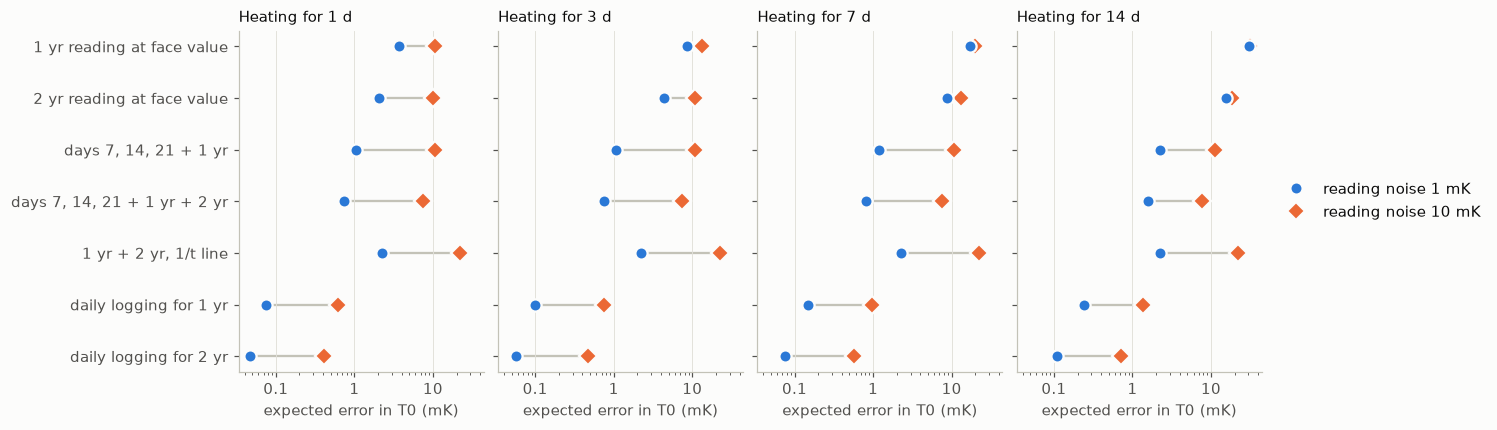

In [24]:
def design_summary(label):
    """Expected error (mK) of each design for one heating duration: {design: {reading noise: expected error}}."""
    ds_case = heating_runs[label]
    T0 = float(ds_case.attrs["T0"])

    def expected(method_error_K, noise_factor):
        return {noise: np.hypot(1e3 * method_error_K, noise_factor * noise) for noise in reading_noise_mK}

    summary = {
        "1 yr reading at face value": expected(borehole_temperature(ds_case, 365)[0] - T0, 1.0),
        "2 yr reading at face value": expected(borehole_temperature(ds_case, 730)[0] - T0, 1.0),
        "days 7, 14, 21 + 1 yr": expected(*all_design_errors[label]["days 7, 14, 21 + 1 yr"]["time shift, all"]),
        "days 7, 14, 21 + 1 yr + 2 yr": expected(*all_design_errors[label]["days 7, 14, 21 + 1 yr + 2 yr"]["time shift, all"]),
        "1 yr + 2 yr, 1/t line": expected(*all_design_errors[label]["1 yr + 2 yr"]["1/t line, last 2"]),
    }
    for years in logging_years:
        summary[f"daily logging for {years} yr"] = {noise: best_first_day(scans[years][label], TIME_SHIFT, noise)[1]
                                                     for noise in reading_noise_mK}
    return summary


def plot_design_summary(labels=tuple(heating_runs)):
    """Expected error of each design at each reading-noise level, one panel per heating duration."""
    styles = dict(zip(reading_noise_mK, [("o", SERIES_COLOURS[0], 4), ("D", SERIES_COLOURS[1], 3)]))   # marker, colour, order
    fig, axes = plt.subplots(1, len(labels), figsize=(13.5, 3.8), sharex=True, sharey=True, squeeze=False)
    for ax, label in zip(axes[0], labels):
        summary = design_summary(label)
        for row, expected in enumerate(summary.values()):
            ax.plot(list(expected.values()), [row] * len(expected), color=AXIS_LINE, linewidth=1.5, zorder=1)
            for noise, (marker, colour, order) in styles.items():
                ax.plot(expected[noise], row, marker, markersize=8, color=colour, markeredgecolor=SURFACE,
                        markeredgewidth=1.5, linestyle="none", zorder=order,
                        label=f"reading noise {noise:g} mK" if row == 0 else None)
        ax.set_xscale("log")
        ax.xaxis.set_major_formatter("{x:g}")
        ax.set_title(f"Heating for {label}")
        ax.set_xlabel("expected error in T0 (mK)")
        ax.grid(axis="y", visible=False)
    axes[0, 0].set_yticks(range(len(summary)), list(summary))
    axes[0, 0].invert_yaxis()
    axes[0, -1].legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
    return fig


fig = plot_design_summary()

### What this shows

These numbers are for the default parameters (background −5 °C, wall held at 0 °C, borehole radius 5 cm). They scale with $T_\mathrm{hot} - T_0$, so for ice at −25 °C they are five times larger.

**One return visit or two**

- A reading taken at face value is 17 mK too warm after one year and 9 mK after two, for 7 days of heating (4 and 2 mK for 1 day). A second visit halves the error of a face-value reading.
- Once the one-year reading is combined with readings from days 7, 14 and 21 and extrapolated, the method error is already small: within 0.5 mK with the free time shift and within 2.6 mK with a 1/t line through day 21 and one year, for 7 days of heating. Adding a two-year reading changes this little.
- A 1/t line through the one-year and two-year readings alone is within 0.3 mK for every heating duration and needs no early readings, but it multiplies reading noise by 2.2.

**A logger or a few readings**

- A few readings in the first three weeks plus one at a year give a method error of a few millikelvin or less, but the estimate carries the full noise of the single late reading (noise factor about 1.1). In the last figure these designs sit at about the level of the reading noise.
- A logger gives a similar method error and averages the noise down by about a factor of ten. For 7 days of heating its expected error after one year is 0.15 to 0.5 mK with 1 mK of reading noise and 0.9 to 1.6 mK with 10 mK. Running it for a second year roughly halves these.
- Readings from the first three weeks alone are not enough. Without a return visit the better fits have noise factors of 4 to 8, and after 7 days of heating their method error is still 6 mK.

**Pitfalls**

- A plain 1/t fit through early and late readings together is worse than the late reading on its own: 36 mK for days 7, 14 and 21 plus one year, against 17 mK for the one-year reading alone (7 days of heating). The early readings lie furthest along the 1/t axis and dominate the fit.
- The last early reading should come about three heating durations after heating ends. If the early readings stop after one week, the errors for 7 days of heating grow to 5.7 mK (1/t line) and 2.6 mK (time shift).
- The ln(1 + s/t) line is the most accurate two-reading estimate, but it moves by about 1.5 mK if the heating duration is wrong by a factor of two (7 days of heating).
- Rule of thumb for the 1/t fit: a line through readings taken around time $t$ leaves a fraction of about $s/(s + 2t)$ of the disturbance present at that time.

To try other cases, edit `designs`, `estimators`, `reading_noise_mK`, `logging_years` or `recovery_sweeps` above and rerun sections 9 to 11.

These errors are in the temperature. Section 12 asks what they mean for the purpose of the measurements, which is to date the grounding of the ice rise.

## 12. Is the schedule accurate enough to date the grounding?

The reason for measuring the temperature profile is to work out when the ice rise grounded. The [vertical temperature notebook](vertical-temperature-after-grounding.ipynb) finds how precisely the temperatures must be known for that. With the geothermal flux, accumulation rate, surface temperature and velocity profile also unknown, dating the grounding to within 10 % needs sensor errors of about 60, 30, 20 and 10 mK if the ice grounded 1,000, 2,000, 3,000 and 5,000 years ago. Those figures are for errors that are independent from one sensor to the next, and they leave out the heat left by drilling.

The heat left by drilling is a different kind of error. Section 11 gives it as a fraction of $T_\mathrm{hot} - T_0$, so along a borehole it is that fraction of how far the ice is below the melting point at each sensor: a smooth error, with the same sign everywhere, that is largest in the cold ice near the surface. This section passes it through the fit of the vertical notebook to see how far it moves the grounding time. It uses the sensor temperatures and sensitivities which that notebook saves in `grounding_time_sensitivity.nc`.

Three things then contribute to the error in the grounding time:

1. **Heat left by drilling** that the schedule does not remove. It moves the grounding time in one direction: a bias.
2. **Noise in the readings**, multiplied by the noise factor of the schedule. It is random, and logging averages it down.
3. **Calibration errors of the sensors.** They differ between sensors but do not change with time, so no schedule reduces them. They act like reading noise with a noise factor of 1.

Two of the vertical notebook's cases are used: only the grounding time is fitted (case 1), and the geothermal flux, accumulation rate, surface temperature and velocity exponent are fitted along with it (case 2).

How long the hole wall stays at the melting point may differ with depth, since cold ice refreezes a hole faster. The heating scenarios below therefore include two in which the heating duration increases from the top sensor to the bed.

Uncertainty of the grounding time for independent sensor errors of 10 mK, case 2, 1,000 years after grounding: 15.9 years (the vertical notebook gives 16)
Ice temperature at the sensors 2,000 years after grounding: -26.6 °C at 20 m to -12.1 °C at the bed


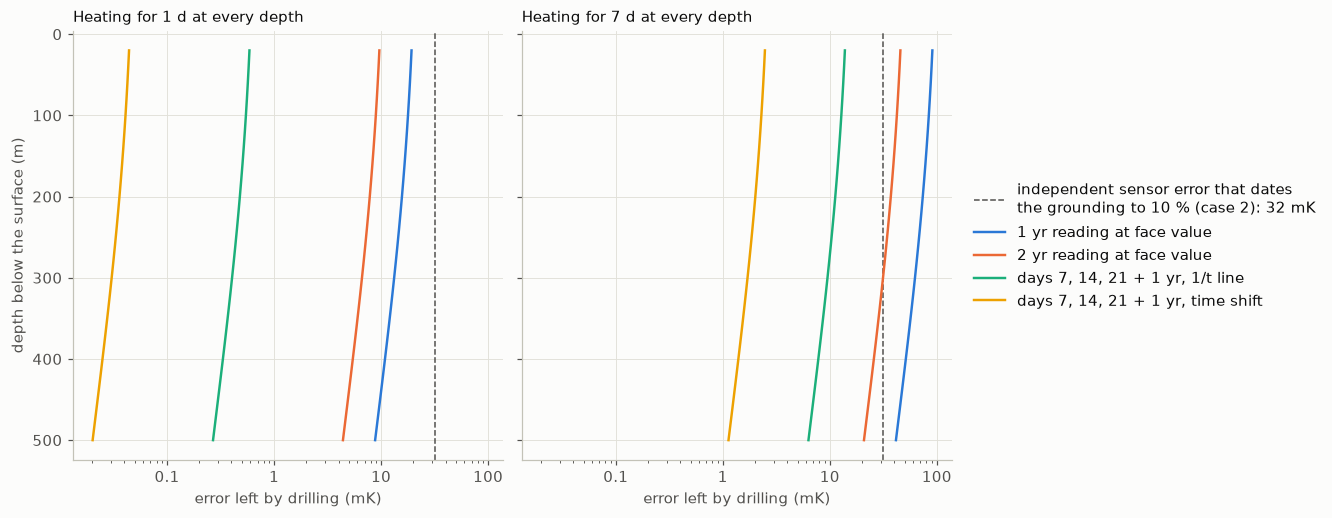

In [25]:
sensitivity_file = "grounding_time_sensitivity.nc"
if not os.path.exists(sensitivity_file):
    raise FileNotFoundError(f"{sensitivity_file} not found. Run vertical-temperature-after-grounding.ipynb first: "
                            "it writes this file.")
with xr.open_dataset(sensitivity_file) as file:
    vertical = file.load()
grounding_ages = vertical["age"].values   # times since grounding (years)
sensor_depths = vertical["depth"].values  # depth of each sensor below the surface (m)
sensor_T = vertical["T"].values           # ice temperature at each sensor, (age, sensor), °C
# Which quantities are fitted along with the grounding time: the first two cases of the vertical notebook
fit_cases = dict(zip(["case 1", "case 2"], list(json.loads(vertical.attrs["cases"]).values())[:2]))

# Heating duration (days) at the top sensor and at the bed. It varies linearly with depth in between.
heating_scenarios = {
    "1 d at every depth": (1.0, 1.0),
    "7 d at every depth": (7.0, 7.0),
    "1 d at the top, 7 d at the bed": (1.0, 7.0),
    "1 d at the top, 14 d at the bed": (1.0, 14.0),
}
shown_ages = [500, 1000, 2000, 3000, 5000]   # times since grounding (years) listed in the tables


def age_index(age):
    """Index of the saved time since grounding nearest to `age` (years)."""
    return int(np.argmin(np.abs(grounding_ages - age)))


def grounding_fit(age, unknowns):
    """Linearised least-squares fit of the vertical model to the sensor temperatures, at one time since grounding.

    The grounding time is fitted together with the quantities named in `unknowns`. Returns
    (response, sd_per_K). response @ b is the change in each fitted quantity, the time since
    grounding first (years), caused by an error b (K) at the sensors. sd_per_K is the standard
    deviation of the time since grounding (years) per kelvin of independent error at every sensor.
    """
    J = vertical["sensitivity"].sel(unknown=["age", *unknowns]).values[:, age_index(age), :].T   # (sensor, unknown)
    scale = np.sqrt((J**2).sum(axis=0))   # unit columns keep the matrix well conditioned
    covariance = np.linalg.inv((J / scale).T @ (J / scale))
    return covariance @ (J / scale).T / scale[:, np.newaxis], np.sqrt(covariance[0, 0]) / scale[0]


# Sections 9 to 11 were run with this difference between the hole wall and the ice. Dividing by it
# gives errors per kelvin below the melting point, which apply at any ice temperature.
T_difference = params["T_hot"] - params["T0"]
heating_days_of_runs = np.array([float(ds_case.attrs["heating_days"]) for ds_case in heating_runs.values()])


def schedules_per_kelvin(label, logger_noise_mK):
    """Method error per kelvin below the melting point, and noise factor, of each schedule after `label` of heating.

    The logger is fitted from the first day that minimises its expected error at the coldest sensor.
    """
    ds_case, errors = heating_runs[label], all_design_errors[label]
    face_value = lambda day: ((borehole_temperature(ds_case, day)[0] - float(ds_case.attrs["T0"])) / T_difference, 1.0)
    fitted = lambda design, estimator: (errors[design][estimator][0] / T_difference, errors[design][estimator][1])
    table = {
        "1 yr reading at face value": face_value(365),
        "2 yr reading at face value": face_value(730),
        "days 7, 14, 21 + 1 yr, 1/t line": fitted("days 7, 14, 21 + 1 yr", "1/t line, last 2"),
        "days 7, 14, 21 + 1 yr, time shift": fitted("days 7, 14, 21 + 1 yr", "time shift, all"),
        "days 7, 14, 21 + 1 yr + 2 yr, time shift": fitted("days 7, 14, 21 + 1 yr + 2 yr", "time shift, all"),
        "1 yr + 2 yr, 1/t line": fitted("1 yr + 2 yr", "1/t line, last 2"),
    }
    coldest = params["T_hot"] - sensor_T.min()   # K below the melting point at the coldest sensor
    for years in logging_years:
        first_days, results = scans[years][label]
        method_error, noise_factor = results[TIME_SHIFT]
        best = np.argmin(np.hypot(1e3 * method_error / T_difference * coldest, noise_factor * logger_noise_mK))
        table[f"daily logging for {years} yr"] = (method_error[best] / T_difference, noise_factor[best])
    return table


per_kelvin = {label: schedules_per_kelvin(label, max(reading_noise_mK)) for label in heating_runs}
schedule_names = list(next(iter(per_kelvin.values())))


def schedule_at_sensors(schedule, scenario):
    """Method error per kelvin at each sensor, and the largest noise factor, of a schedule in a heating scenario.

    Interpolates between the runs of different heating duration, in the logarithm of the duration.
    """
    top, bed = heating_scenarios[scenario]
    heating = top + (bed - top) * (sensor_depths - sensor_depths.min()) / np.ptp(sensor_depths)
    values = np.array([per_kelvin[label][schedule] for label in heating_runs])   # (run, 2)
    log_heating, log_runs = np.log(heating), np.log(heating_days_of_runs)
    return np.interp(log_heating, log_runs, values[:, 0]), np.interp(log_heating, log_runs, values[:, 1]).max()


def residual_at_sensors(schedule, scenario, age):
    """Error (K) that a schedule leaves in the temperature at each sensor, from the heat left by drilling."""
    fraction, _ = schedule_at_sensors(schedule, scenario)
    return fraction * (params["T_hot"] - sensor_T[age_index(age)])


def grounding_time_bias(schedule, scenario, age, unknowns):
    """Bias (years) of the time since grounding caused by the heat a schedule leaves behind.

    Negative means the grounding looks more recent than it was.
    """
    return (grounding_fit(age, unknowns)[0] @ residual_at_sensors(schedule, scenario, age))[0]


def plot_residual_profiles(scenarios, schedules, age=2000):
    """Error left in the temperature at each sensor by some schedules, one panel per heating scenario."""
    needed_mK = 1e3 * 0.1 * grounding_ages[age_index(age)] / grounding_fit(age, fit_cases["case 2"])[1]
    fig, axes = plt.subplots(1, len(scenarios), figsize=(6.0 * len(scenarios), 4.6), sharex=True, sharey=True, squeeze=False)
    for ax, scenario in zip(axes[0], scenarios):
        ax.axvline(needed_mK, color=INK_SOFT, linewidth=1, linestyle="--",
                   label=f"independent sensor error that dates\nthe grounding to 10 % (case 2): {needed_mK:.0f} mK")
        for schedule, colour in zip(schedules, SERIES_COLOURS):
            ax.plot(1e3 * np.abs(residual_at_sensors(schedule, scenario, age)), sensor_depths, color=colour, label=schedule)
        ax.set_xscale("log")
        ax.xaxis.set_major_formatter("{x:g}")
        ax.set_xlabel("error left by drilling (mK)")
        ax.set_title(f"Heating for {scenario}")
    axes[0, 0].invert_yaxis()
    axes[0, 0].set_ylabel("depth below the surface (m)")
    axes[0, -1].legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
    return fig


# Check: the saved sensitivities reproduce the vertical notebook's result for 10 mK sensors, case 2, 1,000 years
print(f"Uncertainty of the grounding time for independent sensor errors of 10 mK, case 2, 1,000 years after "
      f"grounding: {grounding_fit(1000, fit_cases['case 2'])[1] * 0.010:.1f} years (the vertical notebook gives 16)")
print(f"Ice temperature at the sensors 2,000 years after grounding: {sensor_T[age_index(2000)].min():.1f} °C at "
      f"{sensor_depths[0]:g} m to {sensor_T[age_index(2000)].max():.1f} °C at the bed")
fig = plot_residual_profiles(["1 d at every depth", "7 d at every depth"],
                             ["1 yr reading at face value", "2 yr reading at face value",
                              "days 7, 14, 21 + 1 yr, 1/t line", "days 7, 14, 21 + 1 yr, time shift"])

### Bias from the heat left by drilling

The tables give the bias in the time since grounding, in years, for each schedule and each heating scenario. Each cell holds the value for case 1 and then for case 2. A negative value means the grounding looks more recent than it was. The logger is fitted from the first day that minimises its expected error at the coldest sensor for the larger of the two reading-noise levels.

In [26]:
def format_years_error(years):
    """Signed number of years for the tables, with one decimal below 10."""
    return f"{years:+.0f}" if abs(years) >= 10 else f"{years:+.1f}"


for scenario in heating_scenarios:
    print(f"\nHeating for {scenario}: bias in the time since grounding (years), case 1 / case 2")
    print(" " * 42 + "".join(f"{f'{age:,} yr':>17}" for age in shown_ages))
    for schedule in schedule_names:
        cells = [" / ".join(format_years_error(grounding_time_bias(schedule, scenario, age, unknowns))
                            for unknowns in fit_cases.values()) for age in shown_ages]
        print(f"{schedule:<42}" + "".join(f"{cell:>17}" for cell in cells))

# Where the error goes in case 2 when the heating duration is the same at every depth
response, _ = grounding_fit(2000, fit_cases["case 2"])
absorbed = dict(zip(["age", *fit_cases["case 2"]],
                    response @ residual_at_sensors("1 yr reading at face value", "7 d at every depth", 2000)))
print(f"\nCase 2, 7 d of heating at every depth, 1 yr reading at face value, 2,000 years after grounding. The fit "
      f"puts the drilling error into:\n  surface temperature {absorbed['T_surface']:+.3f} K, geothermal flux "
      f"{1e3 * absorbed['geothermal_flux']:+.2f} mW/m², time since grounding {absorbed['age']:+.2f} years")

# Check of the linearised bias against a direct refit of the time since grounding (case 1)
in_time = CubicSpline(grounding_ages, sensor_T)   # sensor temperatures at any time since grounding
print("\nCheck (case 1, 7 d of heating at every depth, 1 yr reading at face value): linearised bias and direct refit")
for age in shown_ages[:-1]:
    measured = sensor_T[age_index(age)] + residual_at_sensors("1 yr reading at face value", "7 d at every depth", age)
    refit = minimize_scalar(lambda t: np.sum((in_time(t) - measured) ** 2), bounds=(grounding_ages[0], grounding_ages[-1]),
                            method="bounded", options={"xatol": 1e-6}).x
    linear = grounding_time_bias("1 yr reading at face value", "7 d at every depth", age, [])
    print(f"  {age:>5,} years after grounding: linearised {linear:+.1f} years, direct refit {refit - age:+.1f} years")


Heating for 1 d at every depth: bias in the time since grounding (years), case 1 / case 2
                                                     500 yr         1,000 yr         2,000 yr         3,000 yr         5,000 yr
1 yr reading at face value                      -2.0 / -0.0      -3.7 / -0.0      -7.4 / -0.0       -13 / -0.0       -41 / -0.0
2 yr reading at face value                      -1.0 / -0.0      -1.8 / -0.0      -3.7 / -0.0      -6.7 / -0.0       -20 / -0.0
days 7, 14, 21 + 1 yr, 1/t line                 -0.1 / -0.0      -0.1 / -0.0      -0.2 / -0.0      -0.4 / -0.0      -1.2 / -0.0
days 7, 14, 21 + 1 yr, time shift               -0.0 / -0.0      -0.0 / -0.0      -0.0 / -0.0      -0.0 / -0.0      -0.1 / -0.0
days 7, 14, 21 + 1 yr + 2 yr, time shift        -0.0 / -0.0      -0.0 / -0.0      -0.0 / -0.0      -0.0 / -0.0      -0.1 / -0.0
1 yr + 2 yr, 1/t line                           -0.0 / -0.0      -0.0 / -0.0      -0.0 / -0.0      -0.0 / -0.0      -0.0 / -0.0
daily logging

### Uncertainty from noise in the readings

The random part of the error is the reading noise times the noise factor of the schedule, passed through the same fit. The first table gives the standard deviation of the grounding time per millikelvin of independent sensor error, which is also what a calibration error of 1 mK contributes whatever the schedule. The second gives the noise factors, and the third multiplies the two for the larger reading-noise level in case 2.

In [27]:
print("Standard deviation of the time since grounding (years) per mK of independent sensor error")
print(" " * 42 + "".join(f"{f'{age:,} yr':>12}" for age in shown_ages))
for case, unknowns in fit_cases.items():
    print(f"{case:<42}" + "".join(f"{1e-3 * grounding_fit(age, unknowns)[1]:12.2f}" for age in shown_ages))

noise_scenario = "7 d at every depth"
noise_factors = {schedule: schedule_at_sensors(schedule, noise_scenario)[1] for schedule in schedule_names}
noise_mK = max(reading_noise_mK)
print(f"\nNoise factor of each schedule (heating for {noise_scenario}), and the uncertainty of the time since "
      f"grounding (years, 1 s.d.)\nfrom {noise_mK:g} mK of reading noise in case 2. Both scale in proportion to the reading noise.")
print(f"{'':<42}{'noise factor':>14}" + "".join(f"{f'{age:,} yr':>12}" for age in shown_ages))
for schedule, factor in noise_factors.items():
    print(f"{schedule:<42}{factor:14.2f}" + "".join(
        f"{1e-3 * grounding_fit(age, fit_cases['case 2'])[1] * factor * noise_mK:12.1f}" for age in shown_ages))

Standard deviation of the time since grounding (years) per mK of independent sensor error
                                                500 yr    1,000 yr    2,000 yr    3,000 yr    5,000 yr
case 1                                            0.06        0.08        0.13        0.23        0.64
case 2                                            0.46        1.59        6.31       14.75       53.24

Noise factor of each schedule (heating for 7 d at every depth), and the uncertainty of the time since grounding (years, 1 s.d.)
from 10 mK of reading noise in case 2. Both scale in proportion to the reading noise.
                                            noise factor      500 yr    1,000 yr    2,000 yr    3,000 yr    5,000 yr
1 yr reading at face value                          1.00         4.6        15.9        63.1       147.5       532.4
2 yr reading at face value                          1.00         4.6        15.9        63.1       147.5       532.4
days 7, 14, 21 + 1 yr, 1/t line    

### Bias and noise together

The figure puts the two side by side for one heating scenario, against the time since grounding. Solid lines are the size of the bias from the heat left by drilling for four schedules. The grey lines are the random uncertainty from 10 mK of reading noise, for a single late reading and for a logger. The dashed line is 10 % of the time since grounding.

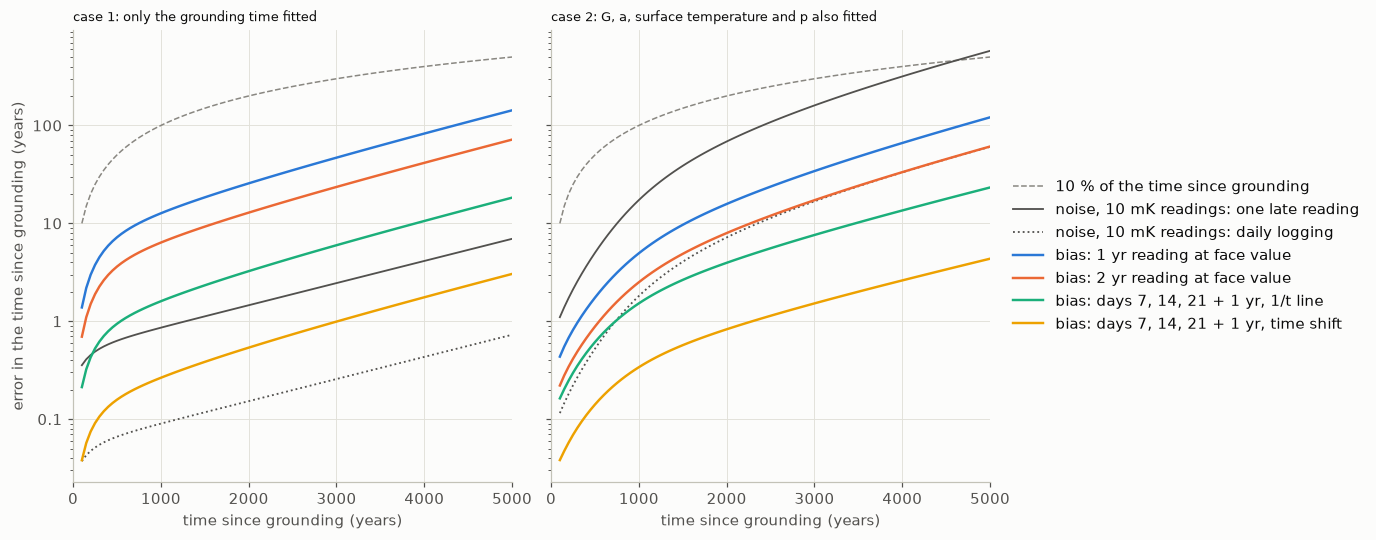

In [28]:
def plot_grounding_time_errors(scenario, schedules, noise_mK=max(reading_noise_mK), floor_years=0.01):
    """Bias and random uncertainty of the time since grounding against the time since grounding, one panel per case.

    Biases smaller than floor_years are drawn at floor_years.
    """
    fig, axes = plt.subplots(1, len(fit_cases), figsize=(6.2 * len(fit_cases), 4.8), sharex=True, sharey=True, squeeze=False)
    for ax, (case, unknowns) in zip(axes[0], fit_cases.items()):
        ax.plot(grounding_ages, 0.1 * grounding_ages, color=INK_MUTED, linewidth=1, linestyle="--",
                label="10 % of the time since grounding")
        sd_per_mK = np.array([1e-3 * grounding_fit(age, unknowns)[1] for age in grounding_ages])
        for schedule, line_style in (("days 7, 14, 21 + 1 yr, time shift", "-"), ("daily logging for 1 yr", ":")):
            ax.plot(grounding_ages, sd_per_mK * schedule_at_sensors(schedule, scenario)[1] * noise_mK, color=INK_SOFT,
                    linewidth=1.2, linestyle=line_style,
                    label=f"noise, {noise_mK:g} mK readings: " + ("one late reading" if line_style == "-" else "daily logging"))
        for schedule, colour in zip(schedules, SERIES_COLOURS):
            bias = np.array([grounding_time_bias(schedule, scenario, age, unknowns) for age in grounding_ages])
            ax.plot(grounding_ages, np.maximum(np.abs(bias), floor_years), color=colour, label=f"bias: {schedule}")
        ax.set_yscale("log")
        ax.yaxis.set_major_formatter("{x:g}")
        ax.set_xlim(0, grounding_ages.max())
        ax.set_xlabel("time since grounding (years)")
        ax.set_title(f"{case}: " + ("only the grounding time fitted" if not unknowns else "G, a, surface temperature and p also fitted"),
                     fontsize="small")
    axes[0, 0].set_ylabel("error in the time since grounding (years)")
    axes[0, -1].legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
    return fig


fig = plot_grounding_time_errors("1 d at the top, 7 d at the bed",
                                 ["1 yr reading at face value", "2 yr reading at face value",
                                  "days 7, 14, 21 + 1 yr, 1/t line", "days 7, 14, 21 + 1 yr, time shift"])

### What this shows

These results are for the default column of the vertical notebook (500 m of ice, −27 °C at the surface, a sensor every 20 m). Its site values are placeholders.

- **After one year the heat left by drilling is not small in millikelvin.** A reading taken at face value is 9 to 20 mK too warm along the borehole after 1 day of heating and 40 to 90 mK after 7 days. That is more than the 32 mK that independent sensor errors may reach if the grounding is to be dated to 10 % at 2,000 years. Readings on days 7, 14 and 21 with the time-shift fit bring it down to 2.5 mK or less.
- **It matters much less than its size suggests, because it is smooth.** Even with no correction, the bias in the grounding time is at most about 5 % of the time since grounding in every case tried: for example 120 to 270 years at 5,000 years when the heating lasts longer near the bed. When the heating duration is the same at every depth and the surface temperature and geothermal flux are fitted (case 2), the fit puts the error into those two (+0.09 K and −0.2 mW m⁻²) and the grounding time hardly moves.
- **With early readings and a fit, the bias is negligible.** Days 7, 14 and 21 plus one year with the time-shift fit keep it under 1 % in every scenario (40 years at 5,000 years at worst).
- **One return visit is enough.** A second visit halves the bias of a face-value reading. Early readings reduce it far more.
- **Noise in the single late reading matters more than drilling heat.** With 10 mK of reading noise in case 2 it gives 17, 69, 160 and 580 years at 1,000, 2,000, 3,000 and 5,000 years since grounding, and it passes 10 % only near 5,000 years. From about 2,000 years on that is more than the drilling bias of even an uncorrected reading. With 1 mK of noise it is ten times smaller. Daily logging for a year divides it by about ten.
- **Calibration errors are untouched by the schedule.** Per millikelvin they contribute as much as reading noise with a noise factor of 1.

For dating the grounding, then, a few readings in the first three weeks and one a year later are enough to deal with the heat left by drilling. Logging is worth having if the readings are noisy (10 mK or more) and the grounding may be several thousand years old. Beyond that, how well the grounding can be dated is set by the accuracy of the sensors and by the unknowns listed in the vertical notebook, not by the schedule.

### Limits

- The heating scenarios are illustrations. How long the hole wall stays at the melting point at each depth is not known, and an error concentrated near the bed, where the grounding leaves its mark, would matter most.
- The fit is linearised. The check above confirms it for case 1 only.
- The two notebooks use slightly different values for the conductivity and heat capacity of ice.
- Everything listed under "What the model leaves out" in the vertical notebook, and the assumptions in section 1 of this one, still apply. In particular the vertical notebook finds that beyond about 2,000 years the grounding time is limited by what is known about the ice when it grounded, whatever the sensors do.

To try other cases, edit `heating_scenarios`, `shown_ages` or `reading_noise_mK` and rerun this section. To change the column, the sensors or the unknowns, edit the vertical notebook, rerun it, and then rerun this section.